# [E-MTAB-6798](https://www.ebi.ac.uk/biostudies/arrayexpress/studies/E-MTAB-6798)

> - Author: Cao Qiang
> - Email: qiangcao2014@gmail.com
> - Created: 2021-04-12
> - Modified: 2025-02-23

# 1. Experimental Design

> Mouse RNA-seq time-series of the development of seven major organs.
> - Cardoso-Moreira, M., Halbert, J., Valloton, D. et al. Gene expression across mammalian organ development. Nature 571, 505–509 (2019). https://doi.org/10.1038/s41586-019-1338-5.
> - poly(A) RNA-seq
> - TruSeq Stranded mRNA LT Sample Prep Kit
> - Illumina HiSeq 2500, PE50
> - mm10

| Pipeline version | iRAP 1.0.1 |
| - | - |
| Analyzed Libraries | See experiment design |
| Filtering Step 1 | Discard reads below minimum quality threshold |
| Filtering Step 2 | Check of bacterial contamination; discard offending reads |
| Filtering Step 3 | Discard reads with common uncalled characters (e.g. N) |
| Filtering Step 4 | Remove reads from pair-end libraries that were orphaned by filtering steps 1-3 |
| Read Mapping | Against genome reference (Ensembl release: 97) HISAT2 version: 2.1.0 |
| Gene Quantification | FeatureCounts version: 1.6.2 |
| Transcript Quantification | kallisto version: 0.42.4 |

# 2. Preprocessing

In [1]:
library(tidyverse)
suppressPackageStartupMessages(library(limma))
suppressPackageStartupMessages(library(edgeR))
suppressPackageStartupMessages(library(DESeq2))
suppressPackageStartupMessages(library(ggrepel))
suppressPackageStartupMessages(library(pheatmap))
suppressPackageStartupMessages(library(patchwork))
suppressPackageStartupMessages(library(RColorBrewer))

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.1     ✔ readr     2.2.0
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.3     ✔ tibble    3.3.1
✔ lubridate 1.9.5     ✔ tidyr     1.3.2
✔ purrr     1.2.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


## 1). Import Data

In [2]:
data_dir <- "~/dataset_1/bulk_omics/rnaseq_Atlas_Embryos_EMTAB2019"

In [3]:
file.path(data_dir, "E-MTAB-6798-atlasExperimentSummary.Rdata") |>
    load(verbose = TRUE)

Loading objects:
  experiment_summary


In [4]:
eSet <- experiment_summary$rnaseq
eSet <- eSet[, eSet$organism_part %in% c("brain", "forebrain")]
eSet

class: RangedSummarizedExperiment 
dim: 55573 55 
metadata(4): pipeline filtering mapping quantification
assays(1): counts
rownames(55573): ENSMUSG00000000001 ENSMUSG00000000003 ...
  ENSMUSG00000118487 ENSMUSG00000118488
rowData names(0):
colnames(55): ERR2588382 ERR2588383 ... ERR2588665 ERR2588666
colData names(8): AtlasAssayGroup organism ... age sex

In [5]:
stage_levels <- c(paste0("E", seq(10.5, 18.5, 1)), paste0("P", c(0,3,14,28,63)))

In [6]:
coldata <- colData(eSet) |> as.data.frame() |>
    rownames_to_column("sample") |>
    mutate(
        age_chr = str_remove(age, " day$"), 
        Stage = paste0(ifelse(developmental_stage == "embryo", "E", "P"), age_chr), 
        Stage = factor(Stage, levels = stage_levels), 
        Sex = factor(sex, levels = c("male", "female"))) |>
    group_by(Stage) |>
    mutate(Replicate = paste0("rep", row_number()) |> factor()) |>
    ungroup() |>
    select(sample, Tissue = organism_part, Stage, Sex , Replicate) |>
    arrange(Stage, Sex, Replicate) |> 
    column_to_rownames("sample") |>
    DataFrame()

coldata

DataFrame with 55 rows and 4 columns
                Tissue    Stage      Sex Replicate
           <character> <factor> <factor>  <factor>
ERR2588382       brain    E10.5   male        rep1
ERR2588383       brain    E10.5   female      rep2
ERR2588384       brain    E10.5   female      rep3
ERR2588402       brain    E11.5   male        rep1
ERR2588403       brain    E11.5   male        rep2
...                ...      ...      ...       ...
ERR2588618   forebrain      P28   female      rep4
ERR2588663   forebrain      P63   male        rep1
ERR2588665   forebrain      P63   male        rep3
ERR2588664   forebrain      P63   female      rep2
ERR2588666   forebrain      P63   female      rep4

In [7]:
anno_gene <- file.path("~/reference/Mus_musculus/mm10", "gencode.vM23.annotation.rds") |>
    readRDS()
anno_gene

GRanges object with 31812 ranges and 3 metadata columns:
                     seqnames          ranges strand |      symbol
                        <Rle>       <IRanges>  <Rle> | <character>
  ENSMUSG00000051951     chr1 3205901-3671498      - |        Xkr4
  ENSMUSG00000089699     chr1 3466587-3513553      + |      Gm1992
  ENSMUSG00000102331     chr1 3647309-3658904      - |     Gm19938
  ENSMUSG00000102343     chr1 3905739-3986215      - |     Gm37381
  ENSMUSG00000025900     chr1 3999557-4409241      - |         Rp1
                 ...      ...             ...    ... .         ...
  ENSMUSG00000065947     chrM      9877-10173      + |     mt-Nd4l
  ENSMUSG00000064363     chrM     10167-11544      + |      mt-Nd4
  ENSMUSG00000064367     chrM     11742-13565      + |      mt-Nd5
  ENSMUSG00000064368     chrM     13552-14070      - |      mt-Nd6
  ENSMUSG00000064370     chrM     14145-15288      + |     mt-Cytb
                               type basepairs
                        <c

## 2). Object Construction

In [8]:
common_genes <- intersect(rownames(eSet), names(anno_gene))

In [9]:
eSet <- eSet[common_genes, rownames(coldata)]
rowRanges(eSet) <- anno_gene[common_genes, ]
colData(eSet) <- coldata
eSet

class: RangedSummarizedExperiment 
dim: 31792 55 
metadata(4): pipeline filtering mapping quantification
assays(1): counts
rownames(31792): ENSMUSG00000000001 ENSMUSG00000000003 ...
  ENSMUSG00000118483 ENSMUSG00000118484
rowData names(3): symbol type basepairs
colnames(55): ERR2588382 ERR2588383 ... ERR2588664 ERR2588666
colData names(4): Tissue Stage Sex Replicate

In [10]:
dds <- DESeqDataSet(eSet, design = ~ Sex + Stage)
dds

class: DESeqDataSet 
dim: 31792 55 
metadata(5): pipeline filtering mapping quantification version
assays(1): counts
rownames(31792): ENSMUSG00000000001 ENSMUSG00000000003 ...
  ENSMUSG00000118483 ENSMUSG00000118484
rowData names(3): symbol type basepairs
colnames(55): ERR2588382 ERR2588383 ... ERR2588664 ERR2588666
colData names(4): Tissue Stage Sex Replicate

In [11]:
dgel <- DGEList(
    counts = assay(eSet), genes = rowRanges(eSet), 
    samples = colData(eSet), group = eSet$Stage)

## 3). Low-Count Filtering

> - Filter low expressed genes to reduce the size of the object and increase the speed of the function

In [12]:
keep <- rowSums(assay(eSet) >= 10) >= 4
# keep <- rowSums(counts(dds) >= 10) >= 4

tab <- table(keep)

cat(
    "Filtered genes summary:\n",
    "Pass:", tab["TRUE"], "\n",
    "Remove:", tab["FALSE"], "\n",
    "Retention rate:", round(tab["TRUE"]/sum(tab)*100, 2), "%\n"
)

eSet <- eSet[keep, ]
dds <- dds[keep, ]

Filtered genes summary:
 Pass: 18265 
 Remove: 13527 
 Retention rate: 57.45 %


In [13]:
keep <- filterByExpr(dgel, group = dgel$samples$group)

tab <- table(keep)

cat(
    "Filtered genes summary:\n",
    "Pass:", tab["TRUE"], "\n",
    "Remove:", tab["FALSE"], "\n",
    "Retention rate:", round(tab["TRUE"]/sum(tab)*100, 2), "%\n"
)

dgel <- dgel[keep, , keep.lib.sizes = FALSE]
# Normalize Library Sizes
dgel <- normLibSizes(dgel)

Filtered genes summary:
 Pass: 18030 
 Remove: 13762 
 Retention rate: 56.71 %


# 3. Normalization

In [14]:
tpm <- assay(eSet) |>
    sweep(1, rowData(eSet)$basepairs, FUN = "/") |>
    (\(rpk) sweep(rpk, 2, colSums(rpk), FUN = "/") * 1e6)()

In [15]:
dds <- estimateSizeFactors(dds)
norm_fpkm <- fpkm(dds, robust = TRUE)

In [16]:
norm_cpm <- cpm(dgel, normalized.lib.sizes = TRUE, log = FALSE)

In [17]:
design <- model.matrix(~ group, data = dgel$samples)
norm_v <- voom(dgel, design, plot = FALSE)

In [18]:
vsd <- vst(dds, blind = FALSE)

In [19]:
suppressPackageStartupMessages(library(vsn))

In [20]:
common_theme <- theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

In [21]:
p1 <- meanSdPlot(log2(counts(dds) + 1), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = expression(-log[2](Count+1))) + 
    common_theme
p2 <- meanSdPlot(log2(tpm + 1), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = expression(-log[2](TPM+1))) + 
    common_theme
p3 <- meanSdPlot(assay(vsd), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = "VST") + 
    common_theme
p4 <- meanSdPlot(log2(norm_fpkm + 1), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = "DESeq2, FPKM") + 
    common_theme
p5 <- meanSdPlot(log2(norm_cpm + 1), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = "edgeR's TMM, CPM") + 
    common_theme
p6 <- meanSdPlot(norm_v$E, ranks = FALSE, plot = FALSE)$gg + 
    labs(title = "limma's voom") + 
    common_theme

Warning message:
“`aes_string()` was deprecated in ggplot2 3.0.0.
ℹ Please use tidy evaluation idioms with `aes()`.
ℹ See also `vignette("ggplot2-in-packages")` for more information.
ℹ The deprecated feature was likely used in the vsn package.
  Please report the issue to the authors.”


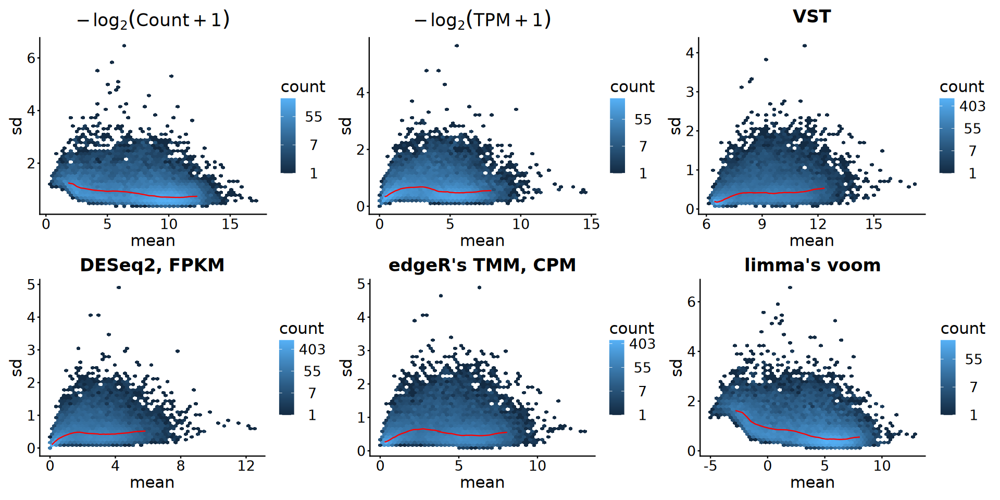

In [22]:
options(repr.plot.width = 16, repr.plot.height = 8)
(p1 + p2 + p3) / (p4 + p5 + p6)

# 4. Exploration

In [23]:
norm_mat <- log2(tpm + 1)
norm_vs <- assay(vsd)

### 1). Overview

In [24]:
plot_df <- colData(eSet) |> as.data.frame() |>
    arrange(Stage, Sex, Replicate) |> 
    rownames_to_column(var = "Sample") |>
    mutate(librarySize = colSums(assay(eSet))[Sample])

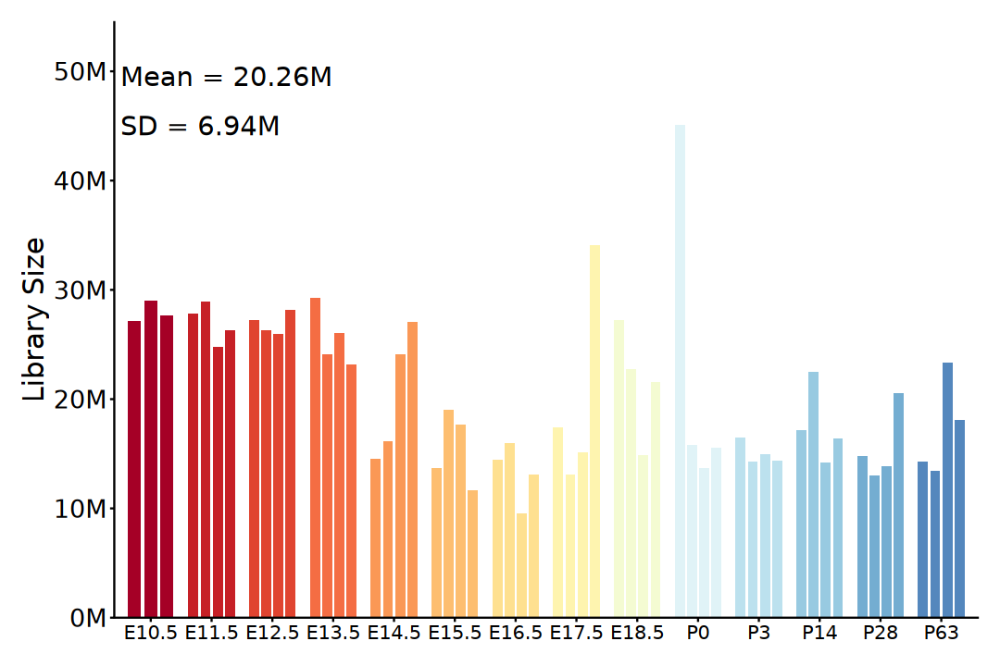

In [25]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(plot_df, aes(x = Stage, y = librarySize)) +
    geom_col(
        aes(fill = Stage, group = Sample), stat = "identity",
        position = position_dodge(width = 0.8),
        width = 0.6, show.legend = FALSE) +
    annotate(
        geom = "text", x = 0.5, y = max(plot_df$librarySize) * 1.1,
        label = paste0("Mean = ", round(mean(plot_df$librarySize) / 1e6, 2), "M"),
        hjust = 0, size = 6) +
    annotate(
        geom = "text", x = 0.5, y = max(plot_df$librarySize) * 1.0,
        label = paste0("SD = ", round(sd(plot_df$librarySize) * 1e-6, 2), "M"),
        hjust = 0, size = 6) +
    scale_y_continuous(
        labels = scales::label_number(scale = 1e-6, suffix = "M"),
        expand = expansion(mult = c(0, 0.1))) +
    scale_fill_manual(
        values = colorRampPalette(brewer.pal(11, "RdYlBu"))(16), 
        na.value = "grey50") +
    labs(x = NULL, y = "Library Size") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        axis.title = element_text(size = 18),
        axis.text.x = element_text(size = 12),
        axis.text.y = element_text(size = 16))

## 2). PCA

In [26]:
top_var_idx <- norm_mat |>
    rowSds() |>
    # (\(m) rowSds(m) / rowMeans2(m))() |> # CV
    tibble::enframe(name = "row", value = "sd") |>
    slice_max(order_by = sd, n = 2000) |>
    pull(row)
# CV can eliminate the bias that "high abundance tends to have large variance".

In [27]:
pca_res <- norm_mat[top_var_idx, ] |> t() |> 
    prcomp(center = TRUE, scale. = FALSE)

per_var <- round(100 * pca_res$sdev^2 / sum(pca_res$sdev^2), 2)

pca_df <- merge(pca_res$x, colData(eSet), by = "row.names")

In [28]:
p1 <- ggplot(pca_df, aes(PC1, PC2)) +
    geom_point(aes(color = Stage, shape = Sex), size = 5) +
    geom_smooth(
        formula = "y ~ x", method = "loess", se = FALSE,
        color = "grey", linewidth = 1) +
    scale_color_manual(
        values = colorRampPalette(brewer.pal(11, "RdYlBu"))(16), 
        na.value = "grey50") +
    labs(
        title = bquote("PCA for" ~ -log[2](TPM+1)), 
        x = paste0("PC1: ", per_var[1], "% variance"),
        y = paste0("PC2: ", per_var[2], "% variance")) +
    guides(
        color = guide_legend(override.aes = list(size = 5)), 
        shape = guide_legend(override.aes = list(size = 5))) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

In [29]:
pca_res <- plotPCA(
    vsd, intgroup = c("Stage", "Sex", "Replicate"), 
    ntop = 2000, returnData = TRUE)

per_var <- round(100 * attr(pca_res, "percentVar"))

using ntop=2000 top features by variance



In [30]:
p2 <- ggplot(pca_res, aes(PC1, PC2)) +
    geom_point(aes(color = Stage, shape = Sex), size = 5) +
    geom_smooth(
        formula = "y ~ x", method = "loess", se = FALSE,
        color = "grey", linewidth = 1) +
    scale_color_manual(
        values = colorRampPalette(brewer.pal(11, "RdYlBu"))(16), 
        na.value = "grey50") +
    labs(
        title = "PCA for rlog", 
        x = paste0("PC1: ", per_var[1], "% variance"),
        y = paste0("PC2: ", per_var[2], "% variance")) +
    guides(
        color = guide_legend(override.aes = list(size = 5)), 
        shape = guide_legend(override.aes = list(size = 5))) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

In [31]:
# Generalized principal component analysis (GLM-PCA)
# suppressPackageStartupMessages(library(glmpca))
set.seed(123)

gpca <- glmpca::glmpca(assay(eSet)[top_var_idx, ], L = 2)

gpca_df <- merge(gpca$factors, colData(eSet), by = "row.names")

In [32]:
p3 <- ggplot(gpca_df, aes(dim1, dim2)) +
    geom_point(aes(color = Stage, shape = Sex), size = 5) +
    geom_smooth(
        formula = "y ~ x", method = "loess", se = FALSE,
        color = "grey", linewidth = 1) +
    scale_color_manual(
        values = colorRampPalette(brewer.pal(11, "RdYlBu"))(16), 
        na.value = "grey50") +
    labs(title = "GLM-PCA for raw count", x = "PC1", y = "PC2") +
    guides(
        color = guide_legend(override.aes = list(size = 5)),
        shape = guide_legend(override.aes = list(size = 5))) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

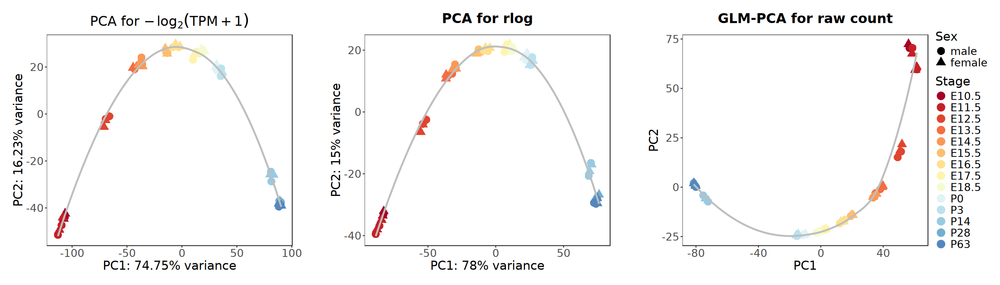

In [33]:
options(repr.plot.width = 21, repr.plot.height = 6)

p1 + plot_spacer() + p2 + plot_spacer() + p3 +
    plot_layout(nrow = 1, guides = "collect", 
                widths = c(1, 0.05, 1, 0.05, 1))

## 3). MDS

> Multidimensional scaling

In [34]:
dist_mat <- norm_mat[top_var_idx, ] |> t() |> dist()

mds <- colData(eSet) |> as.data.frame() |>
    cbind(cmdscale(as.matrix(dist_mat)))

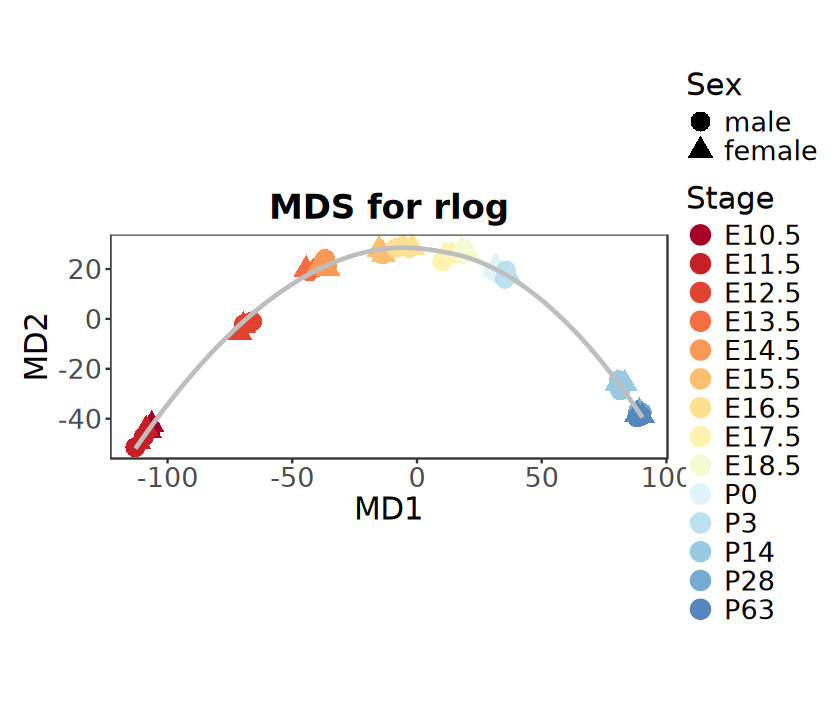

In [35]:
options(repr.plot.width = 7, repr.plot.height = 6)

ggplot(mds, aes(x = `1`, y = `2`)) +
    geom_point(aes(color = Stage, shape = Sex), size = 5) +
    geom_smooth(
        formula = "y ~ x", method = "loess", se = FALSE,
        color = "grey", linewidth = 1) +
    # geom_path(
    #     aes(group = 1), color = "black", 
    #     arrow = arrow(length = unit(0.15, "inches"))) +
    scale_color_manual(
        values = colorRampPalette(brewer.pal(11, "RdYlBu"))(16), 
        na.value = "grey50") +
    coord_fixed() + 
    labs(title = "MDS for rlog", x = "MD1", y = "MD2") +
    guides(
        color = guide_legend(override.aes = list(size = 5)), 
        shape = guide_legend(override.aes = list(size = 5))) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

## 4). PCoA

> Principal coordinate analysis

In [36]:
# 1. Calculate Bray-Curtis distance on the transposed count matrix
dist_mat <- norm_vs[top_var_idx, ] |> t() |> 
    vegan::vegdist(method = "bray")

# 2. Run PCoA
pcoa_res <- cmdscale(dist_mat, k = 2, eig = TRUE)

# 3. Prepare data for plot
pcoa_df <- merge(pcoa_res$points, colData(eSet), by = "row.names")

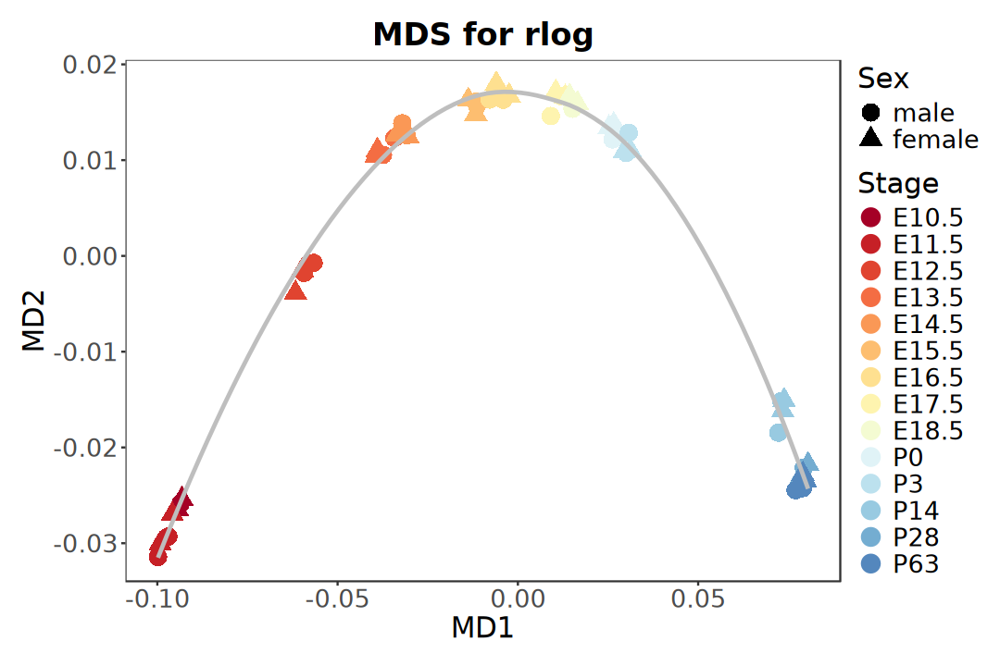

In [37]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(pcoa_df, aes(x = V1, y = V2)) +
    geom_point(aes(color = Stage, shape = Sex), size = 5) +
    geom_smooth(
        formula = "y ~ x", method = "loess", se = FALSE,
        color = "grey", linewidth = 1) +
    scale_color_manual(
        values = colorRampPalette(brewer.pal(11, "RdYlBu"))(16), 
        na.value = "grey50") +
    labs(title = "MDS for rlog", x = "MD1", y = "MD2") +
    guides(
        color = guide_legend(override.aes = list(size = 5)), 
        shape = guide_legend(override.aes = list(size = 5))) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

## 5). Sample Correlation

In [38]:
ac <- colData(eSet) |> as.data.frame() |>
    dplyr::select(Replicate, Sex, Stage)

In [39]:
group_colors <- setNames(
    colorRampPalette(brewer.pal(11, "RdYlBu"))(16),
    levels(eSet$Stage))
sex_colors <- setNames(
    scales::brewer_pal(palette = "Set1")(nlevels(eSet$Sex)),
    levels(eSet$Sex))
replicate_colors <- setNames(
    scales::brewer_pal(palette = "Set2")(nlevels(eSet$Replicate)),
    levels(eSet$Replicate))

anno_colors <- list(
    Stage = group_colors,
    Sex = sex_colors,
    Replicate = replicate_colors)

colors <- colorRampPalette(brewer.pal(9, "Blues"))(255)

In [40]:
dist_mat <- norm_vs[top_var_idx, ] |> t() |> dist()

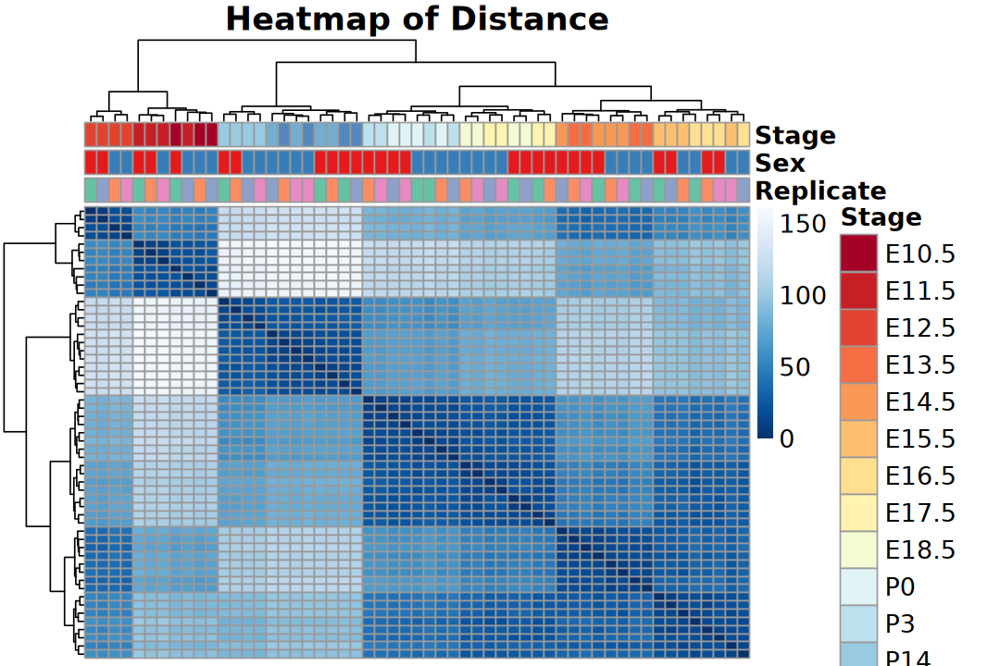

In [41]:
options(repr.plot.width = 9, repr.plot.height = 6)

pheatmap::pheatmap(
    as.matrix(dist_mat),
    clustering_distance_rows = dist_mat,
    clustering_distance_cols = dist_mat,
    annotation_col = ac, col = rev(colors), 
    annotation_colors = anno_colors,
    main = "Heatmap of Distance", fontsize = 16, 
    show_colnames = FALSE, show_rownames = FALSE)

## 6). Sample Correlation

In [42]:
cor_mat <- cor(norm_vs[top_var_idx, ], method = "spearman")

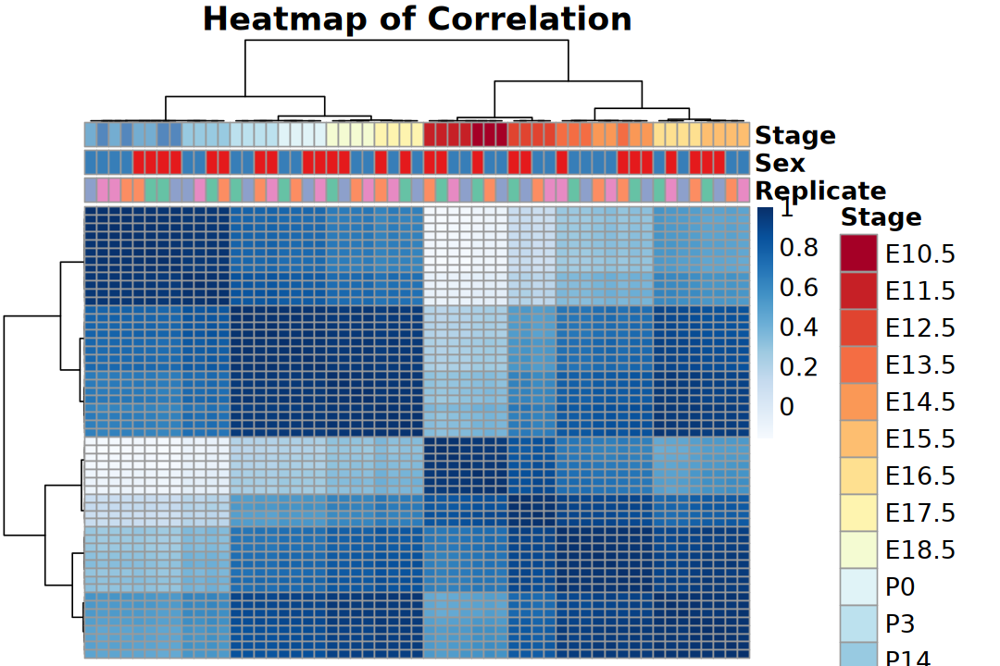

In [43]:
options(repr.plot.width = 9, repr.plot.height = 6)

pheatmap::pheatmap(
    as.matrix(cor_mat), 
    clustering_distance_rows = "correlation",
    clustering_distance_cols = "correlation",
    annotation_col = ac, col = colors, 
    annotation_colors = anno_colors,
    main = "Heatmap of Correlation", fontsize = 16, 
    show_colnames = FALSE, show_rownames = FALSE)

## 7). Heatmap

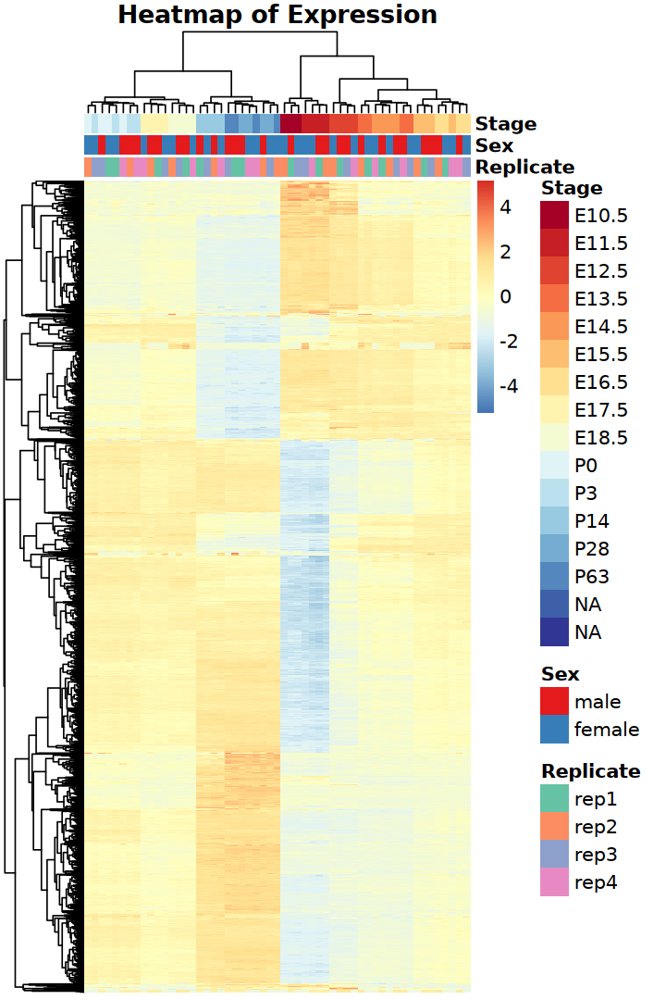

In [44]:
options(repr.plot.width = 6, repr.plot.height = 9)

pheatmap::pheatmap(
    norm_mat[top_var_idx, ], scale = "row", 
    annotation_col = ac, 
    annotation_colors = anno_colors, 
    main = "Heatmap of Expression", fontsize = 12, 
    show_colnames = FALSE, show_rownames = FALSE)

In [45]:
p1 <- pheatmap::pheatmap(
    norm_mat[top_var_idx, ], scale = "row", 
    annotation_col = ac, 
    annotation_colors = anno_colors, 
    main = "Heatmap of Expression", fontsize = 12, 
    show_colnames = FALSE, show_rownames = FALSE, 
    silent = TRUE)

In [46]:
p2 <- pheatmap::pheatmap(
    norm_mat[top_var_idx, ], scale = "row", 
    annotation_col = ac, 
    annotation_colors = anno_colors, 
    main = "Heatmap of Expression", fontsize = 12, 
    show_colnames = FALSE, show_rownames = FALSE, 
    cluster_cols = FALSE, silent = TRUE)

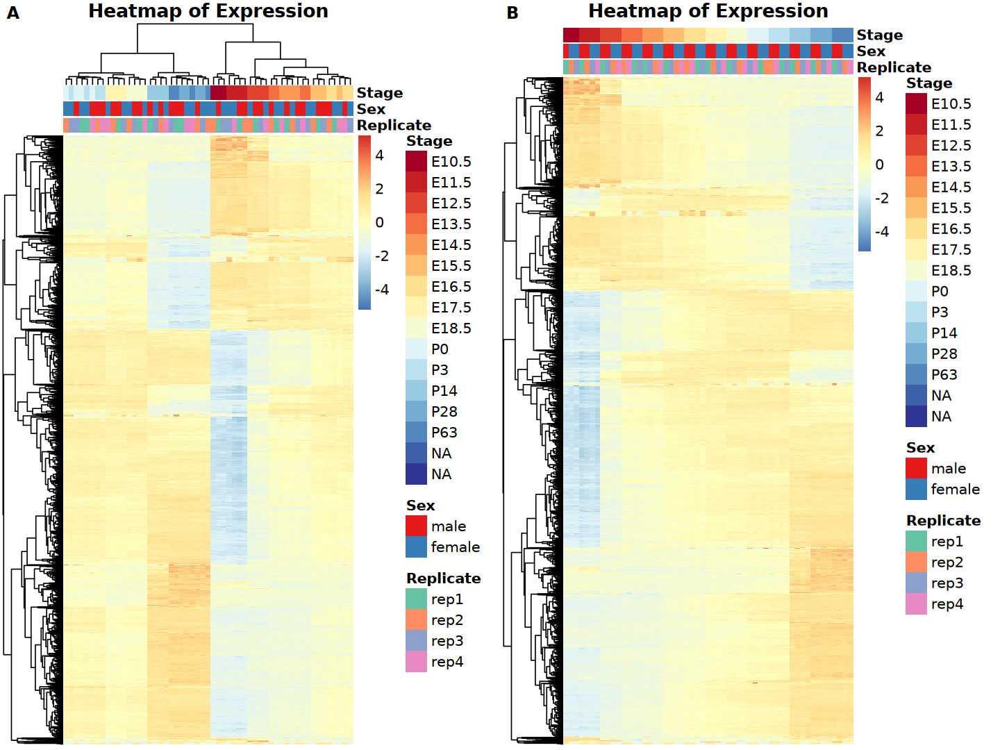

In [47]:
options(repr.plot.width = 12, repr.plot.height = 9)
cowplot::plot_grid(p1[[4]], p2[[4]], labels = c("A", "B"), ncol = 2)

# 5. DEGs: Pairwise

> Sequential pairwise contrast is a differential expression analysis strategy that compares consecutive time points or developmental stages to identify stage-specific transcriptional dynamics. The primary advantage of this localized approach lies in its ability to capture temporal gene expression trajectories and pinpoint critical transition windows with high chronological resolution. However, this sequential strategy inevitably escalates the multiple-testing burden and may overlook cumulative expression changes spanning distant stages. Consequently, it is frequently complemented by global or longitudinal analytical frameworks to achieve a holistic view of the transcriptomic landscape.

# 6. Time-course Dynamics

## 1). DEGs: Dynamic Gene Selection

### a). DESeq2 (LRT)

> The likelihood ratio test (LRT) is useful for testing multiple terms at once, for example testing 3 or more levels of a factor at once, or all interactions between two variables. The LRT for count data is conceptually similar to an analysis of variance (ANOVA) calculation in linear regression, except that in the case of the Negative Binomial GLM, we use an analysis of deviance (ANODEV), where the deviance captures the difference in likelihood between a full and a reduced model.
> - Identifies genes with significant expression dynamics across conditions. By comparing the full factors model against a reduced model, LRT filters out invariant baseline features and captures any temporal patterns  (e.g., monotonic or wave-like), serving as a crucial input for clustering.

In [48]:
design(dds)

~Sex + Stage

In [49]:
dds <- DESeq(dds, test = "LRT", reduced = ~ Sex)

using pre-existing size factors

estimating dispersions

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

fitting model and testing



In [50]:
deseq2_lrt_result <- results(dds) |> as.data.frame() |> 
    rownames_to_column("gene_id") |>
    dplyr::rename(logFC = log2FoldChange) |>
    mutate(
        result = case_when(
            padj < 1e-5  ~ "Sig", TRUE ~ "NS") |> 
            factor(levels = c("Sig", "NS"))) |>
    left_join(
        rowData(dds) |> as.data.frame() |> 
            dplyr::select(symbol, type, basepairs) |>
            rownames_to_column("gene_id"), 
        by = "gene_id") |>
    column_to_rownames("gene_id")

table(deseq2_lrt_result$result)
head(deseq2_lrt_result)


  Sig    NS 
16849  1416 

,baseMean,logFC,lfcSE,stat,pvalue,padj,result,symbol,type,basepairs
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>,<chr>,<int>
ENSMUSG00000000001,3012.465243,-2.7365614,0.1210834,1587.63600,0.000000e+00,0.000000e+00,Sig,Gnai3,protein_coding,3262
ENSMUSG00000000028,397.570968,-5.0816358,0.1554770,5697.51540,0.000000e+00,0.000000e+00,Sig,Cdc45,protein_coding,3506
ENSMUSG00000000031,4813.479654,-11.0826769,0.4549093,1254.57058,3.192392e-260,1.663121e-259,Sig,H19,lncRNA,2460
ENSMUSG00000000037,173.374987,-2.0879977,0.1722900,827.49952,1.775820e-168,6.397506e-168,Sig,Scml2,protein_coding,6397
ENSMUSG00000000049,8.764061,8.4592438,2.1348965,34.47555,1.018682e-03,1.068709e-03,NS,Apoh,protein_coding,1594
ENSMUSG00000000056,1789.644054,-0.3453412,0.0634984,477.59393,8.352413e-94,2.049118e-93,Sig,Narf,protein_coding,4806


### b). edgeR (ANOVA-like)

> ANOVA-like test for any differences. In edgeR, this is done by specifying multiple coefficients to glmQLFTest or glmLRT, when the design matrix includes an intercept term.

In [51]:
design <- model.matrix(~ Sex + Stage, data = dgel$samples)

In [52]:
dgel <- estimateDisp(dgel, design)
fit <- glmQLFit(dgel, design)
qlft <- glmQLFTest(fit, coef = 3:ncol(design))

In [53]:
edgeR_anova_result <- topTags(qlft, n = Inf) |>
    as.data.frame() |> 
    dplyr::rename(padj = FDR, pvalue = PValue) |>
    mutate(
        result = case_when(
            padj < 1e-5  ~ "Sig", TRUE ~ "NS") |>
            factor(levels = c("Sig", "NS")))

table(edgeR_anova_result$result)
head(edgeR_anova_result)


  Sig    NS 
16336  1694 

,seqnames,start,end,width,strand,symbol,type,basepairs,logFC.StageE11.5,logFC.StageE12.5,⋯,logFC.StageP0,logFC.StageP3,logFC.StageP14,logFC.StageP28,logFC.StageP63,logCPM,F,pvalue,padj,result
,<fct>,<int>,<int>,<int>,<fct>,<chr>,<chr>,<int>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>
ENSMUSG00000050966,chr4,134003330,134018841,15512,-,Lin28a,protein_coding,3996,0.7940673,-4.15257848,⋯,-8.7953081,-9.9547947,-9.069525,-9.852465,-9.718615,3.796163,919.0167,1.607623e-69,2.898544e-65,Sig
ENSMUSG00000100147,chr1,182287990,182303325,15336,+,1700047M11Rik,lncRNA,2846,-0.7314146,-0.04096478,⋯,1.5253572,1.6429737,7.681082,8.322063,8.321063,1.298612,333.9059,3.465231e-67,3.123905e-63,Sig
ENSMUSG00000026424,chr1,135160234,135167681,7448,-,Gpr37l1,protein_coding,2269,-1.5774309,-1.57943068,⋯,7.3516781,8.2724744,12.724733,13.016976,13.152582,5.025499,1494.8105,1.630544e-65,7.691165e-62,Sig
ENSMUSG00000050600,chr2,174643534,174710832,67299,+,Zfp831,protein_coding,9807,1.6519710,0.74103077,⋯,3.8816925,4.0504975,8.902160,10.116031,10.037574,2.476519,590.7504,1.706304e-65,7.691165e-62,Sig
ENSMUSG00000050121,chr19,41061710,41077113,15404,-,Opalin,protein_coding,2946,0.2449852,-0.33832642,⋯,-0.8633143,0.3320089,8.772833,10.165877,9.861721,2.370605,427.7935,3.828464e-65,1.380544e-61,Sig
ENSMUSG00000033579,chr8,111345135,111393824,48690,-,Fa2h,protein_coding,3008,-1.3734253,-0.17180054,⋯,2.0209760,2.7584756,9.173790,10.141157,9.828596,3.633475,723.9604,6.746125e-65,2.027211e-61,Sig


In [54]:
comparison_df <- deseq2_lrt_result |> 
    rownames_to_column("gene_id") |>
    dplyr::select(gene_id, result_deseq2 = result) |> 
    inner_join(
        edgeR_anova_result |> 
            rownames_to_column("gene_id") |>
            dplyr::select(gene_id, result_edger = result),
        by = c("gene_id"))

cat("\n=========================================\n")
cat("Contrast:", "Stages", "\n")
cat("=========================================\n")
print(table(
    DESeq2 = comparison_df$result_deseq2, 
    edgeR = comparison_df$result_edger))

Contrast: Stages 
      edgeR
DESeq2   Sig    NS
   Sig 16249   494
   NS     34  1170


## 2). Trend Clustering

> It is recommended to use genes with significant differential expression to enhance computational efficiency. Of course, all genes can also be selected for cluster analysis.

In [55]:
sig_gene_ids <- deseq2_lrt_result |> 
    dplyr::filter(result == "Sig") |> rownames()

message(
    "Number of time-significantly dynamic genes identified by LRT:", 
    length(sig_gene_ids), "\n")

Number of time-significantly dynamic genes identified by LRT:16849




In [56]:
norm_tpm <- assay(eSet) |>
    sweep(1, rowData(eSet)$basepairs, FUN = "/") |>
    (\(rpk) sweep(rpk, 2, colSums(rpk), FUN = "/") * 1e6)()
norm_ltpm <- log2(norm_tpm + 1)
norm_mat <- norm_ltpm[sig_gene_ids, ]

# rld_mat <- assay(rlog(dds, blind = FALSE))
# vst_mat <- assay(vst(dds, blind = FALSE))
# norm_mat <- vst_mat[sig_gene_ids, ]

In [57]:
stages <- eSet$Stage

norm_mean_mat <- sapply(stage_levels, function(stage) {
    rowMeans(norm_mat[, stages == stage, drop = FALSE])
})

print(dim(norm_mean_mat))
print(head(norm_mean_mat))

[1] 16849    14
                       E10.5     E11.5    E12.5    E13.5    E14.5    E15.5
ENSMUSG00000000001  8.303046  8.733957 8.391003 8.092324 7.745109 7.733654
ENSMUSG00000000028  6.335062  6.204854 5.586935 5.359683 5.299192 4.477253
ENSMUSG00000000031 10.308788 10.581040 8.799256 8.484879 8.754771 8.673082
ENSMUSG00000000037  2.698354  2.996750 3.078773 3.048530 2.889545 3.024405
ENSMUSG00000000056  6.103076  6.044719 6.569928 6.638413 6.588593 6.653127
ENSMUSG00000000058  2.527634  2.548423 3.109409 3.233846 2.966927 3.205318
                      E16.5    E17.5    E18.5       P0       P3      P14
ENSMUSG00000000001 7.826696 7.269174 7.984508 7.381104 7.445524 6.093056
ENSMUSG00000000028 4.261946 3.682108 3.081051 3.046349 2.913090 2.050802
ENSMUSG00000000031 8.563202 9.023677 8.184879 7.941146 6.831225 2.920939
ENSMUSG00000000037 3.326846 3.198580 3.543185 3.038106 2.986008 1.155921
ENSMUSG00000000056 6.746702 6.699679 6.861098 6.062674 6.169620 6.292615
ENSMUSG00000000058 3.

### a). Mfuzz

> Soft clustering: fuzzy c-means algorithm (of the e1071 package) based on minimization of a weighted square error function.

In [58]:
suppressPackageStartupMessages(library(Mfuzz))

Warning message:
“no DISPLAY variable so Tk is not available”


In [59]:
# Filtering of genes based on their standard deviation
cl_eset <- ExpressionSet(assayData = norm_mean_mat) |>
    filter.std(min.std = 0.5, visu = FALSE) |>
    standardise()
cl_eset

7754 genes excluded.


ExpressionSet (storageMode: lockedEnvironment)
assayData: 9095 features, 14 samples 
  element names: exprs 
protocolData: none
phenoData: none
featureData: none
experimentData: use 'experimentData(object)'
Annotation:  

In [60]:
# Estimate for optimal fuzzifier m
m_val <- mestimate(cl_eset)
message(paste0("fuzzifier m: ", m_val))

set.seed(123)
cl_mfuzz <- mfuzz(cl_eset, c = 6, m = m_val)
cl_mfuzz$cluster |> table()

fuzzifier m: 1.18151090720368




   1    2    3    4    5    6 
1108 2141 1357  736 1495 2258 

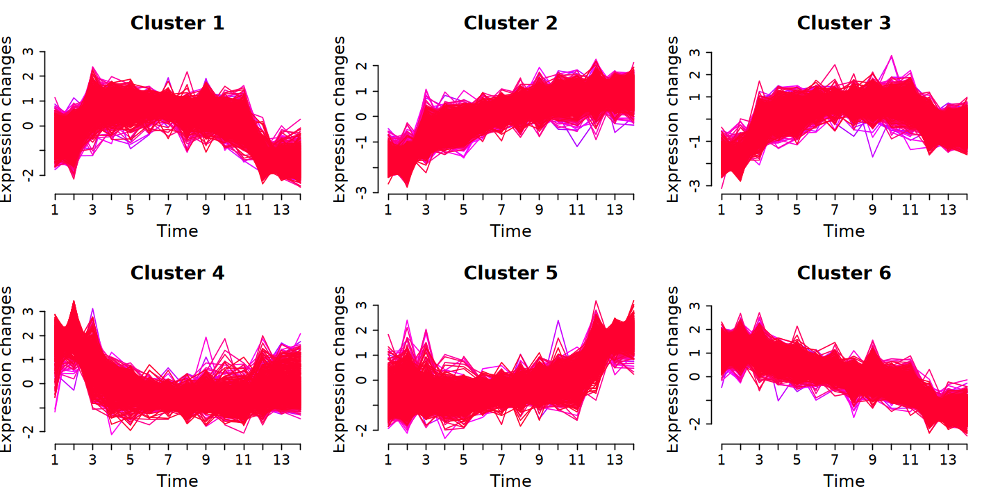

In [61]:
options(repr.plot.width = 12, repr.plot.height = 6)

mfuzz.plot2(
    cl_eset, cl = cl_mfuzz, mfrow = c(2, 3), 
    min.mem = 0.8, x11 = FALSE, cex.main = 2,
    cex.lab = 1.8, cex.axis = 1.5)

### b). TCseq

In [62]:
suppressPackageStartupMessages(library(TCseq))

Warning message:
“replacing previous import ‘e1071::element’ by ‘ggplot2::element’ when loading ‘TCseq’”


In [63]:
norm_mean_filtered_tpm <- norm_mean_mat[rowSds(norm_mean_mat) >= 0.5, ]

set.seed(123)
cl_tcseq <- timeclust(
    norm_mean_filtered_tpm, algo = "cm", k = 6, standardize = TRUE)
cl_tcseq@cluster |> table()


   1    2    3    4    5    6 
1095 1890 1418 1389 1491 1812 

Warning message:
“The `size` argument of `element_line()` is deprecated as of ggplot2 3.4.0.
ℹ Please use the `linewidth` argument instead.
ℹ The deprecated feature was likely used in the TCseq package.
  Please report the issue to the authors.”


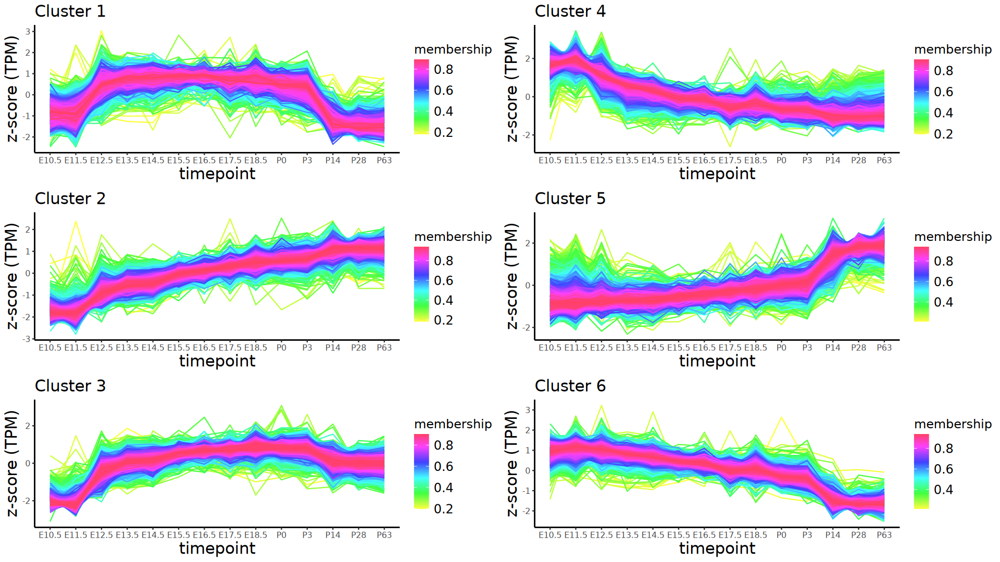

In [64]:
options(repr.plot.width = 16, repr.plot.height = 9)

p <- timeclustplot(
    cl_tcseq, value = "z-score (TPM)", cols = 2, axis.text.size = 9)

### [TiSA](https://github.com/Ylefol/TimeSeriesAnalysis)?

PART clustering

- Yohan Lefol, Tom Korfage, Robin Mjelle, Christian Prebensen, Torben Lüders, Bruno Müller, Hans Krokan, Antonio Sarno, Lene Alsøe, CONSORTIUM LEMONAID, Jan-Erik Berdal, Pål Sætrom, Hilde Nilsen, Diana Domanska, TiSA: TimeSeriesAnalysis—a pipeline for the analysis of longitudinal transcriptomics data, NAR Genomics and Bioinformatics, Volume 5, Issue 1, March 2023, lqad020, https://doi.org/10.1093/nargab/lqad020.

## 3). Regression

### a). maSigPro

> maSigPro follows a two-step regression strategy to find genes with significant temporal expression changes and significant differences between experimental groups.

In [65]:
suppressPackageStartupMessages(library(maSigPro))

In [66]:
design_df <- colData(eSet) |> as.data.frame() |> 
    mutate(
        Time = as.integer(Stage), 
        Replicate = as.integer(Replicate), 
        Group = 1) |> 
    dplyr::select(Time, Replicate, Group) |>
    arrange(Time, Replicate)

head(design_df)

,Time,Replicate,Group
,<int>,<int>,<dbl>
ERR2588382,1,1,1
ERR2588383,1,2,1
ERR2588384,1,3,1
ERR2588402,2,1,1
ERR2588403,2,2,1
ERR2588404,2,3,1


In [67]:
# Defining the regression model
# degree = time points - 1
# Usually, a polynomial of degree 2 is more than enough to model the gene expression, 
# although a degree 3 may be appropriate in experacimental setups with a big number of
# time points.
design <- make.design.matrix(design_df, degree = 3)

In [68]:
# dgel <- estimateGLMCommonDisp(dgel, design = design)
# phi <- dgel$common.dispersion
# theta <- 1/phi
1 / dgel$common.dispersion

[1] 58.40696

In [69]:
# DEseq2
# norm_counts <- counts(dds, normalized = TRUE)

# # edgeR
# eff_lib_size <- dgel$samples$lib.size * dgel$samples$norm.factors
# norm_counts <- t(t(dgel$counts) / eff_lib_size) * mean(eff_lib_size)

# TPM
norm_counts <- norm_ltpm

In [70]:
# Performs regression analysis for each gene to identify significant ones.
fit <- p.vector(
    norm_counts, design, counts = TRUE, 
    theta = 60, Q = 0.05, MT.adjust = "BH")

[1] "fitting  gene 100 out of 18265"
[1] "fitting  gene 200 out of 18265"
[1] "fitting  gene 300 out of 18265"
[1] "fitting  gene 400 out of 18265"
[1] "fitting  gene 500 out of 18265"
[1] "fitting  gene 600 out of 18265"
[1] "fitting  gene 700 out of 18265"
[1] "fitting  gene 800 out of 18265"
[1] "fitting  gene 900 out of 18265"
[1] "fitting  gene 1000 out of 18265"
[1] "fitting  gene 1100 out of 18265"
[1] "fitting  gene 1200 out of 18265"
[1] "fitting  gene 1300 out of 18265"
[1] "fitting  gene 1400 out of 18265"
[1] "fitting  gene 1500 out of 18265"
[1] "fitting  gene 1600 out of 18265"
[1] "fitting  gene 1700 out of 18265"
[1] "fitting  gene 1800 out of 18265"
[1] "fitting  gene 1900 out of 18265"
[1] "fitting  gene 2000 out of 18265"
[1] "fitting  gene 2100 out of 18265"
[1] "fitting  gene 2200 out of 18265"
[1] "fitting  gene 2300 out of 18265"
[1] "fitting  gene 2400 out of 18265"
[1] "fitting  gene 2500 out of 18265"
[1] "fitting  gene 2600 out of 18265"
[1] "fitting  gene 27

In [71]:
print(fit$i)

[1] 17759


In [72]:
# Selects the best regression model for each gene using stepwise regression.
tstep <- T.fit(fit, step.method = "backward", alfa = 0.05)

[1] "fitting  gene 100 out of 17759"
[1] "fitting  gene 200 out of 17759"
[1] "fitting  gene 300 out of 17759"
[1] "fitting  gene 400 out of 17759"
[1] "fitting  gene 500 out of 17759"
[1] "fitting  gene 600 out of 17759"
[1] "fitting  gene 700 out of 17759"
[1] "fitting  gene 800 out of 17759"
[1] "fitting  gene 900 out of 17759"
[1] "fitting  gene 1000 out of 17759"
[1] "fitting  gene 1100 out of 17759"
[1] "fitting  gene 1200 out of 17759"
[1] "fitting  gene 1300 out of 17759"
[1] "fitting  gene 1400 out of 17759"
[1] "fitting  gene 1500 out of 17759"
[1] "fitting  gene 1600 out of 17759"
[1] "fitting  gene 1700 out of 17759"
[1] "fitting  gene 1800 out of 17759"
[1] "fitting  gene 1900 out of 17759"
[1] "fitting  gene 2000 out of 17759"
[1] "fitting  gene 2100 out of 17759"
[1] "fitting  gene 2200 out of 17759"
[1] "fitting  gene 2300 out of 17759"
[1] "fitting  gene 2400 out of 17759"
[1] "fitting  gene 2500 out of 17759"
[1] "fitting  gene 2600 out of 17759"
[1] "fitting  gene 27

In [73]:
sigs <- get.siggenes(tstep, rsq = 0.6, vars = "all")

In [74]:
summary(sigs)
sig_gene_ids <- sigs$summary

cat("Number of significant time-varying genes:", length(sig_gene_ids), "\n")

          Length Class  Mode     
sig.genes     7  -none- list     
summary   10901  -none- character

Number of significant time-varying genes: 10901 


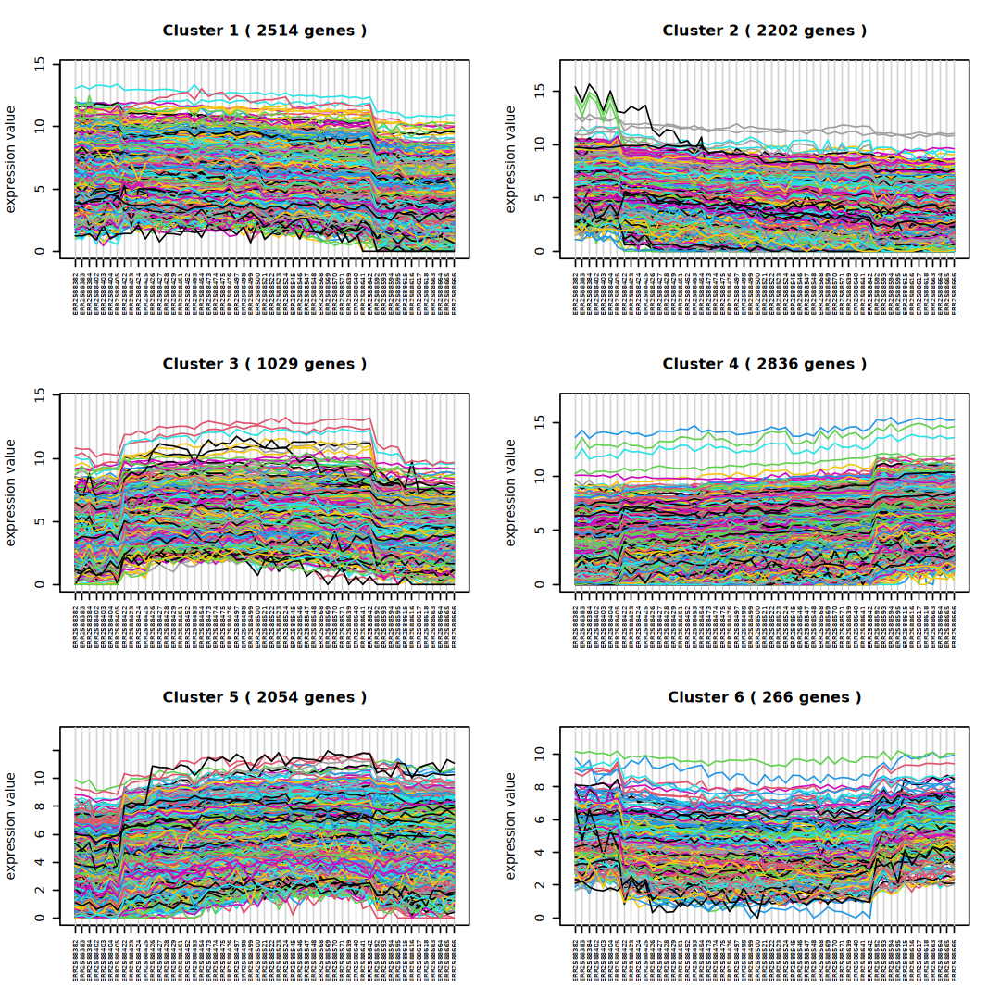

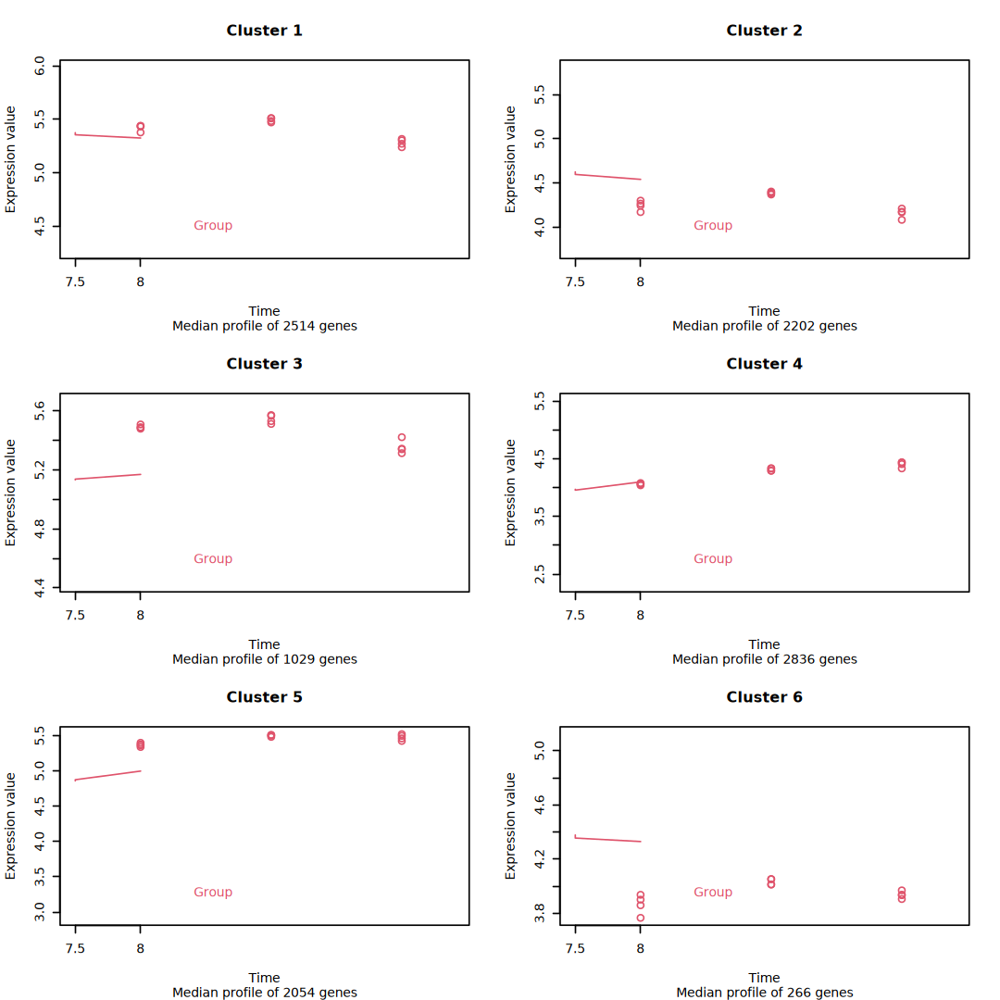

In [75]:
options(repr.plot.width = 9, repr.plot.height = 9)
cl_masigpro <- see.genes(sigs$sig.genes, k = 6)

In [76]:
cl_masigpro$cut |> table()


   1    2    3    4    5    6 
2514 2202 1029 2836 2054  266 

## 4). WGCNA

## 5). Impulse Model

### ImpulseDE2?
- David S Fischer, Fabian J Theis, Nir Yosef, Impulse model-based differential expression analysis of time course sequencing data, Nucleic Acids Research, Volume 46, Issue 20, 16 November 2018, Page e119, https://doi.org/10.1093/nar/gky675.

In [77]:
# library(ImpulseDE2)
# # inputData: data.frame(sample, time, condition), raw counts矩阵
# res <- runImpulseDE2(matCount = counts, dfAnnotation = meta,
#                     boolCaseCtrl = FALSE, scaNProc = 4)
# head(res$vecDEGene)

## Clustering Evaluation

### Adjusted Rand Index, ARI

In [78]:
suppressPackageStartupMessages(library(mclust))

In [79]:
gene_lists <- list(
    names(cl_mfuzz$cluster),
    names(cl_tcseq@cluster),
    names(cl_masigpro$cut))

common_genes <- Reduce(intersect, gene_lists)

vector_mfuzz    <- cl_mfuzz$cluster[common_genes]
vector_tcseq    <- cl_tcseq@cluster[common_genes]
vector_masigpro <- cl_masigpro$cut[common_genes]

In [80]:
ari_mfuzz_tcseq    <- adjustedRandIndex(vector_mfuzz, vector_tcseq)
ari_mfuzz_masigpro <- adjustedRandIndex(vector_mfuzz, vector_masigpro)
ari_tcseq_masigpro <- adjustedRandIndex(vector_tcseq, vector_masigpro)

cat("ARI (Mfuzz vs tcseq):", ari_mfuzz_tcseq, "\n")
cat("ARI (Mfuzz vs maSigPro):", ari_mfuzz_masigpro, "\n")
cat("ARI (tcseq vs maSigPro):", ari_tcseq_masigpro, "\n")

ARI (Mfuzz vs tcseq): 0.676701 
ARI (Mfuzz vs maSigPro): 0.4413781 
ARI (tcseq vs maSigPro): 0.5583136 


### Jaccard Similarity

In [81]:
table_match <- table(vector_mfuzz, vector_tcseq)

jaccard_matrix <- matrix(
    0, nrow=nrow(table_match), ncol=ncol(table_match),
    dimnames=list(
        paste0("Mfuzz_C", rownames(table_match)), 
        paste0("TCseq_C", colnames(table_match))))

for(i in 1:nrow(table_match)) {
    for(j in 1:ncol(table_match)) {
        intersection <- table_match[i, j]
        union_size <- sum(vector_mfuzz == rownames(table_match)[i]) + 
            sum(vector_tcseq == colnames(table_match)[j]) - intersection
        jaccard_matrix[i, j] <- intersection / union_size
    }
}

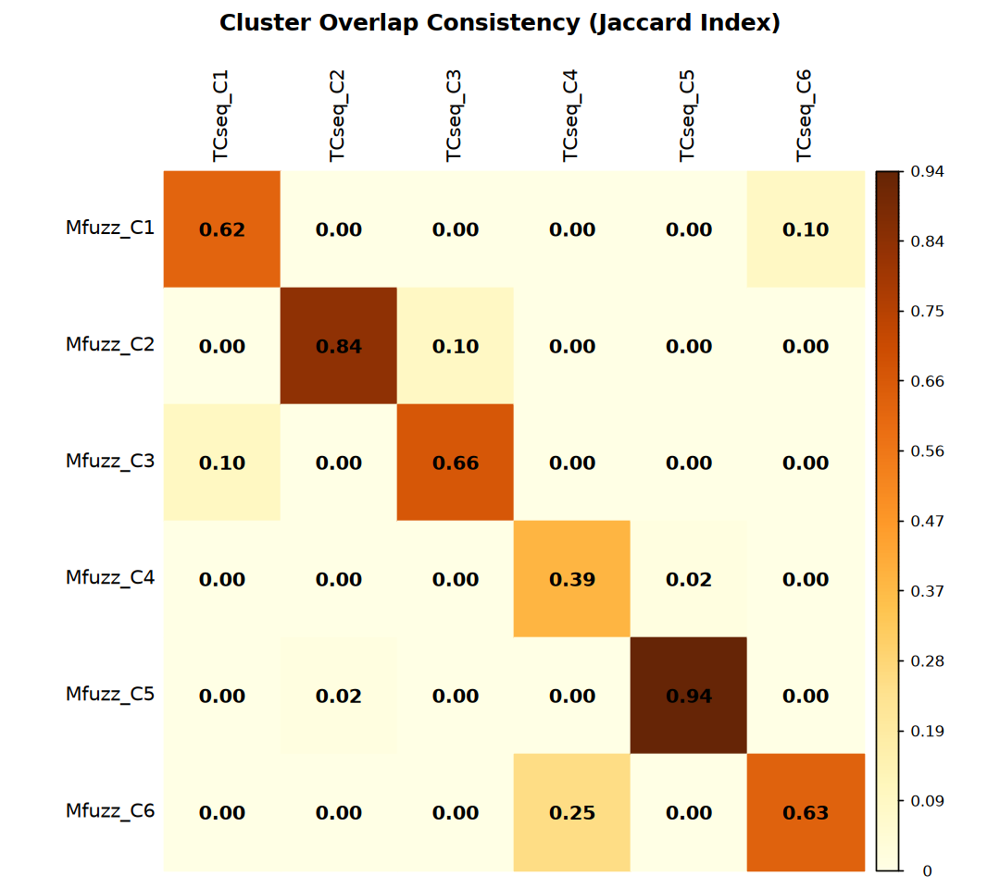

In [82]:
options(repr.plot.width = 9, repr.plot.height = 8)
corrplot::corrplot(
    jaccard_matrix, is.corr = FALSE, method = "color", 
    addCoef.col = "black", tl.col = "black", 
    title = "Cluster Overlap Consistency (Jaccard Index)", 
    mar = c(0,0,2,0))

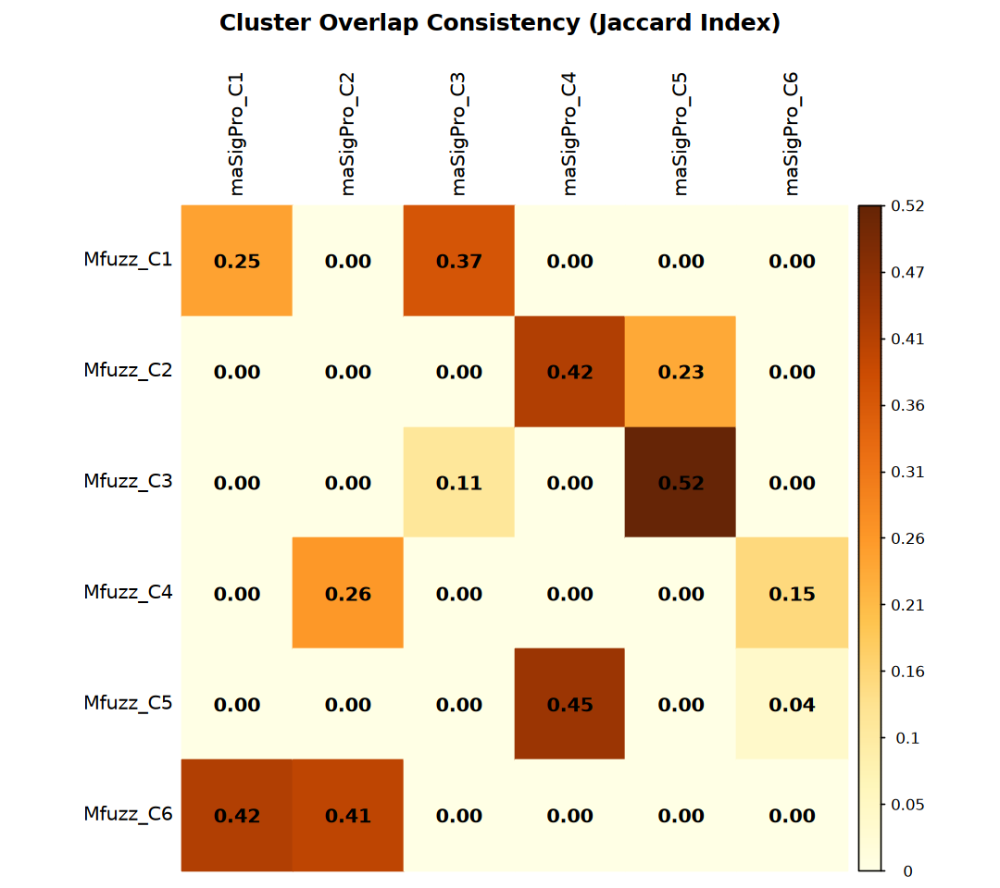

In [83]:
table_match <- table(vector_mfuzz, vector_masigpro)

jaccard_matrix <- matrix(
    0, nrow=nrow(table_match), ncol=ncol(table_match),
    dimnames=list(
        paste0("Mfuzz_C", rownames(table_match)), 
        paste0("maSigPro_C", colnames(table_match))))

for(i in 1:nrow(table_match)) {
    for(j in 1:ncol(table_match)) {
        intersection <- table_match[i, j]
        union_size <- sum(vector_mfuzz == rownames(table_match)[i]) + 
            sum(vector_masigpro == colnames(table_match)[j]) - intersection
        jaccard_matrix[i, j] <- intersection / union_size
    }
}

options(repr.plot.width = 9, repr.plot.height = 8)
corrplot::corrplot(
    jaccard_matrix, is.corr = FALSE, method = "color", 
    addCoef.col = "black", tl.col = "black", 
    title = "Cluster Overlap Consistency (Jaccard Index)", 
    mar = c(0,0,2,0))

## Clustering Visualization

### Lineplot

In [84]:
norm_mat <- log2(tpm + 1)

In [85]:
norm_expr_df <- norm_mat |> as.data.frame() |>
    rownames_to_column(var = "gene_id") |>
    pivot_longer(cols = -gene_id, names_to = "sample", values_to = "value")

In [86]:
plot_lineplot <- function(cluster, expression, coldata, group, method) {
    data.frame(cluster = cluster) |>
        rownames_to_column(var = "gene_id") |>
        mutate(cluster = factor(paste0("cluster", cluster))) |>
        add_count(cluster, name = "count") |>
        left_join(expression, by = "gene_id") |>
        left_join(coldata, by = "sample") |>
        group_by(across(all_of(group)), Replicate, cluster, count) |>
        summarize(
            median_value = median(value, na.rm = TRUE), 
            .groups = "drop") |>
        mutate(
            cluster_label = paste0(cluster, " (n=", count, ")"),
            cluster_label = factor(cluster_label)) |>
        ungroup() |>
    ggplot(aes(x = .data[[group]], y = median_value)) +
        # geom_point(position = position_jitter(width = 0.1), alpha = 0.7) + 
        stat_summary(
            aes(color = cluster_label, group = cluster_label), 
            fun = mean, geom = "line", linewidth = 1, alpha = 0.8) +
        stat_summary(
            aes(color = cluster_label, group = cluster_label), 
            fun.data = mean_se, geom = "errorbar", width = 0.1) +
        scale_x_discrete(expand = expansion(mult = c(0.1, 0.1))) +
        scale_y_continuous(expand = expansion(mult = c(0.1, 0.1))) +
        scale_color_brewer(palette = "Set3") +
        labs(
            title = paste0("Time-course: ", method), 
            color = "Cluster", x = NULL, y = "Median Expression") +
        theme_classic() +
        theme(
            plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
            plot.margin = unit(c(1, 1, 1, 1), "line"),
            axis.title = element_text(size = 18), 
            axis.text = element_text(size = 16),
            legend.title = element_text(size = 18),
            legend.text = element_text(size = 16))
}

In [87]:
coldata <- colData(eSet) |> as.data.frame() |> 
    rownames_to_column(var = "sample")

p1 <- plot_lineplot(
    cluster = cl_mfuzz$cluster, expression = norm_expr_df, 
    coldata = coldata, group = "Stage", method = "Mfuzz")
p2 <- plot_lineplot(
    cluster = cl_tcseq@cluster, expression = norm_expr_df, 
    coldata = coldata, group = "Stage", method = "TCseq")
p3 <- plot_lineplot(
    cluster = cl_masigpro$cut, expression = norm_expr_df, 
    coldata = coldata, group = "Stage", method = "maSigPro")

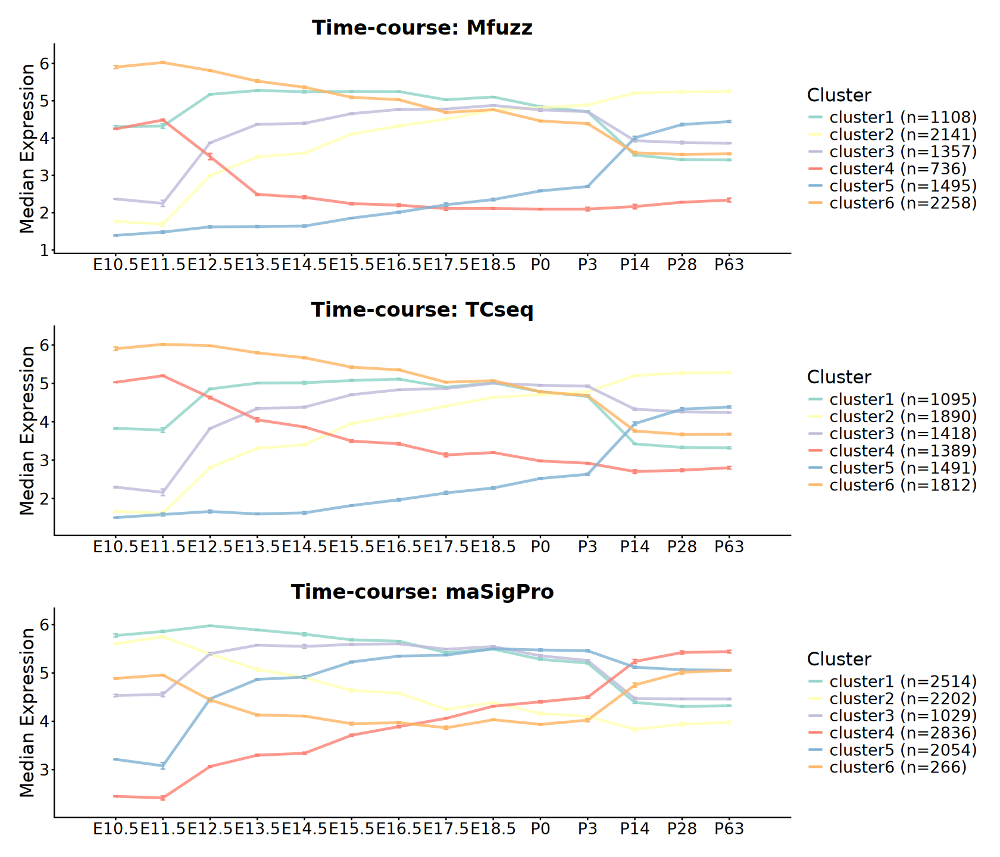

In [88]:
options(repr.plot.width = 14, repr.plot.height = 12)
p1 / p2 / p3

### Heatmap

In [89]:
ac <- colData(dds) |> 
    as.data.frame() |>
    dplyr::select(Replicate, Sex, Stage)

In [90]:
ar <- cl_mfuzz$cluster |> data.frame(Cluster = _) |>
    mutate(Cluster = factor(paste0("cluster", Cluster))) |>
    arrange(Cluster)

In [91]:
heatmap_dat <- norm_mat[rownames(ar), ]

In [92]:
group_colors <- setNames(
    colorRampPalette(brewer.pal(11, "RdYlBu"))(nlevels(dds$Stage)),
    levels(dds$Stage))
sex_colors <- setNames(
    scales::brewer_pal(palette = "Set1")(nlevels(dds$Sex)),
    levels(dds$Sex))
replicate_colors <- setNames(
    scales::brewer_pal(palette = "Set2")(nlevels(dds$Replicate)),
    levels(dds$Replicate))

anno_colors <- list(
    Stage = group_colors,
    Sex = sex_colors,
    Replicate = replicate_colors)

colors <- colorRampPalette(brewer.pal(9, "Blues"))(255)

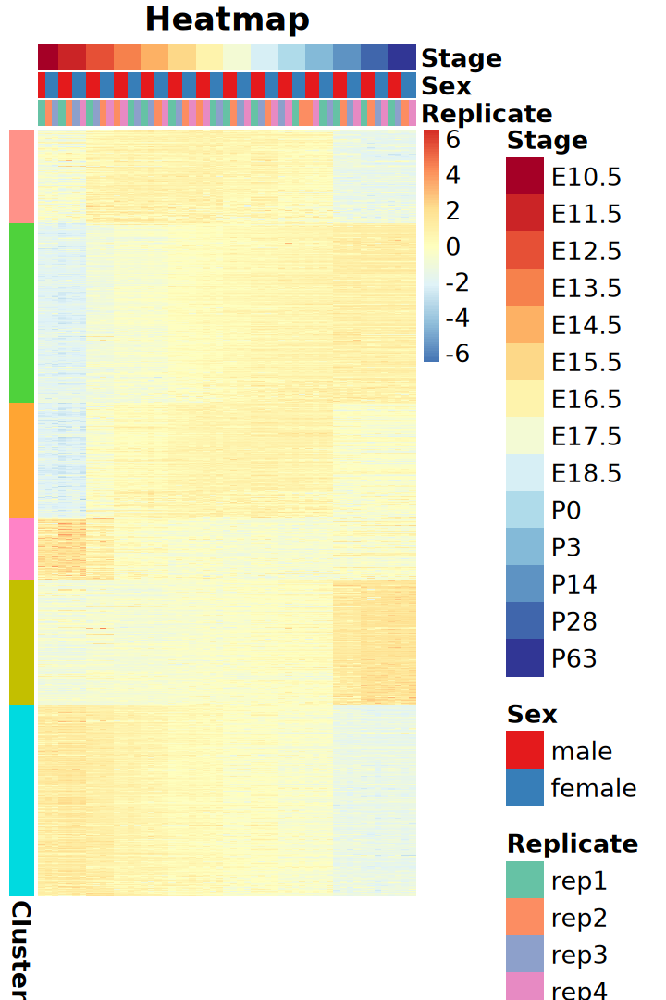

In [93]:
options(repr.plot.width = 6, repr.plot.height = 9)
pheatmap::pheatmap(
    heatmap_dat, scale = "row", 
    cluster_rows = FALSE, cluster_cols = FALSE,
    annotation_row = ar, annotation_col = ac,
    annotation_colors = anno_colors,
    main = "Heatmap", fontsize = 16, 
    show_colnames = FALSE, show_rownames = FALSE)

# 7. Gene Function Analysis

## 1). ORA

> Over-Representation Analysis

In [94]:
suppressPackageStartupMessages(library(org.Mm.eg.db))
suppressPackageStartupMessages(library(clusterProfiler))

In [95]:
gene_map <- bitr(
    rowData(dds)$symbol, OrgDb = org.Mm.eg.db, fromType = "SYMBOL", 
    toType = c("ENTREZID"), drop = FALSE)

'select()' returned 1:1 mapping between keys and columns

Warning message in bitr(rowData(dds)$symbol, OrgDb = org.Mm.eg.db, fromType = "SYMBOL", :
“6.31% of input gene IDs are fail to map...”


In [96]:
membership_df <- cl_mfuzz$membership |> 
    as.data.frame() |> 
    rownames_to_column(var = "gene_id") |> 
    pivot_longer(cols = -gene_id, names_to = "cluster", values_to = "membership")

In [97]:
cluster_df <- cl_mfuzz$cluster |> 
    data.frame(cluster = _) |>
    mutate(cluster = as.character(cluster)) |>
    rownames_to_column(var = "gene_id") |>
    left_join(membership_df, by = c("gene_id", "cluster")) |>
    filter(membership > 0.6) |>
    left_join(
        rowData(dds) |> as.data.frame() |> 
        dplyr::select(symbol, type) |>
        rownames_to_column("gene_id"), 
        by = "gene_id") |>
    left_join(gene_map, by = c("symbol" = "SYMBOL"))

table(cluster_df$cluster)
head(cluster_df)


   1    2    3    4    5    6 
1056 2061 1310  699 1441 2190 

,gene_id,cluster,membership,symbol,type,ENTREZID
,<chr>,<chr>,<dbl>,<chr>,<chr>,<chr>
1,ENSMUSG00000000001,6,0.9998995,Gnai3,protein_coding,14679
2,ENSMUSG00000000028,6,0.9999987,Cdc45,protein_coding,12544
3,ENSMUSG00000000031,6,0.9881712,H19,lncRNA,14955
4,ENSMUSG00000000037,1,0.9976159,Scml2,protein_coding,107815
5,ENSMUSG00000000078,3,0.9844249,Klf6,protein_coding,23849
6,ENSMUSG00000000093,6,0.7426570,Tbx2,protein_coding,21385


In [98]:
# membership_df <- cl_tcseq@membership |> 
#     as.data.frame() |> 
#     rownames_to_column(var = "gene_id") |> 
#     pivot_longer(cols = -gene_id, names_to = "cluster", values_to = "membership")

# cluster_df <- cl_tcseq@cluster |> 
#     data.frame(cluster = _) |>
#     mutate(cluster = as.character(cluster)) |>
#     rownames_to_column(var = "gene_id") |>
#     left_join(membership_df, by = c("gene_id", "cluster")) |>
#     filter(membership > 0.6) |>
#     left_join(
#         rowData(dds) |> as.data.frame() |> 
#         dplyr::select(symbol, type) |>
#         rownames_to_column("gene_id"), 
#         by = "gene_id") |>
#     left_join(gene_map, by = c("gene_id" = "ENSEMBL"))

# table(cluster_df$cluster)

In [99]:
gene_list <- split(cluster_df$symbol, cluster_df$cluster)

In [100]:
ego_cluster_compare <- compareCluster(
    geneCluster = gene_list, fun = enrichGO,
    universe = rowData(dds)$symbol, 
    OrgDb = org.Mm.eg.db, ont = "ALL", 
    keyType = 'SYMBOL', pAdjustMethod = "BH",
    pvalueCutoff = 0.01, qvalueCutoff = 0.05, 
    minGSSize = 10, maxGSSize = 500, readable = TRUE)

In [101]:
ego_cluster_compare |> dplyr::select(-geneID) |> head()

,Cluster,ONTOLOGY,ID,Description,GeneRatio,BgRatio,RichFactor,FoldEnrichment,zScore,pvalue,p.adjust,qvalue,Count
,<fct>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>
1,1,BP,GO:0030900,forebrain development,59/830,452/15295,0.1305310,2.405387,7.265152,2.938745e-10,1.260428e-06,1.242316e-06,59
2,1,BP,GO:0021879,forebrain neuron differentiation,22/830,97/15295,0.2268041,4.179481,7.524701,7.831157e-09,1.163428e-05,1.146710e-05,22
3,1,BP,GO:0021953,central nervous system neuron differentiation,40/830,272/15295,0.1470588,2.709957,6.816035,8.137758e-09,1.163428e-05,1.146710e-05,40
4,1,BP,GO:0021872,forebrain generation of neurons,22/830,107/15295,0.2056075,3.788875,6.934434,5.244713e-08,5.623643e-05,5.542833e-05,22
5,1,BP,GO:0021537,telencephalon development,41/830,306/15295,0.1339869,2.469072,6.218103,7.778866e-08,6.672712e-05,6.576827e-05,41
6,1,BP,GO:0021543,pallium development,32/830,210/15295,0.1523810,2.808032,6.319511,1.102809e-07,7.883245e-05,7.769966e-05,32


In [102]:
gene_list <- split(cluster_df$ENTREZID, cluster_df$cluster)

In [103]:
ekegg_cluster_compare <- compareCluster(
    geneCluster = gene_list, fun = enrichKEGG, 
    universe = unique(gene_map$ENTREZID), 
    organism = "mmu", pAdjustMethod = "BH",
    pvalueCutoff = 0.01, qvalueCutoff = 0.05, 
    minGSSize = 10, maxGSSize = 500)

In [104]:
ekegg_cluster_compare |> dplyr::select(-geneID) |> head()

,Cluster,category,subcategory,ID,Description,GeneRatio,BgRatio,RichFactor,FoldEnrichment,zScore,pvalue,p.adjust,qvalue,Count
,<fct>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>
1,1,Genetic Information Processing,Chromosome,mmu03083,Polycomb repressive complex,16/291,78/6828,0.2051282,4.813111,7.145738,1.235227e-07,3.421578e-05,3.172582e-05,16
2,1,Cellular Processes,Cellular community - eukaryotes,mmu04550,Signaling pathways regulating pluripotency of stem cells,19/291,127/6828,0.1496063,3.510350,6.024743,1.469287e-06,2.034962e-04,1.886874e-04,19
3,1,Human Diseases,Cancer: specific types,mmu05225,Hepatocellular carcinoma,20/291,161/6828,0.1242236,2.914772,5.187249,1.438078e-05,1.327825e-03,1.231196e-03,20
4,2,Environmental Information Processing,Signaling molecules and interaction,mmu04082,Neuroactive ligand signaling,81/790,184/6828,0.4402174,3.804816,13.950198,1.395493e-29,4.423712e-27,3.481387e-27,81
5,2,Environmental Information Processing,Signaling molecules and interaction,mmu04080,Neuroactive ligand-receptor interaction,90/790,286/6828,0.3146853,2.719837,10.747242,2.365526e-20,3.749359e-18,2.950682e-18,90
6,2,Environmental Information Processing,Signal transduction,mmu04024,cAMP signaling pathway,70/790,201/6828,0.3482587,3.010013,10.462137,1.115045e-18,1.178231e-16,9.272481e-17,70


### Clustered Heatmap

In [105]:
norm_mat <- log2(tpm + 1)

#### 1). Heatmap-ggplot2

In [106]:
plot_df <- norm_mat |> t() |> scale() |> t() |> 
    as.data.frame() |> 
    rownames_to_column("gene_id") |>
    pivot_longer(cols = -gene_id, names_to = "sample", values_to = "expression") |>
    right_join(cluster_df, by = "gene_id") |>
    mutate(
        sample = factor(sample, levels = colnames(dds)), 
        cluster = as.factor(cluster)) |>
    arrange(cluster, membership, sample, expression)

head(plot_df)

gene_id,sample,expression,cluster,membership,symbol,type,ENTREZID
<chr>,<fct>,<dbl>,<fct>,<dbl>,<chr>,<chr>,<chr>
ENSMUSG00000058446,ERR2588382,-1.5006152,1,0.6011551,Znrf2,protein_coding,387524
ENSMUSG00000058446,ERR2588383,-1.1929266,1,0.6011551,Znrf2,protein_coding,387524
ENSMUSG00000058446,ERR2588384,-1.4958973,1,0.6011551,Znrf2,protein_coding,387524
ENSMUSG00000058446,ERR2588402,-0.9523337,1,0.6011551,Znrf2,protein_coding,387524
ENSMUSG00000058446,ERR2588403,-0.8923303,1,0.6011551,Znrf2,protein_coding,387524
ENSMUSG00000058446,ERR2588404,-1.1843704,1,0.6011551,Znrf2,protein_coding,387524


In [107]:
line_plot <- ggplot(plot_df, aes(x = sample, y = expression)) +
    geom_path(
        aes(group = gene_id, color = membership),
        linewidth = 0.5, alpha = 0.5) +
    scale_color_distiller(
        palette = "RdYlBu", limits = c(0, 1), 
        breaks = seq(0, 1, 0.5)) +
    scale_y_continuous(breaks = c(-2, 0, 2)) + 
    facet_wrap(
        ~ cluster, ncol = 1, strip.position = "left",
        labeller = "label_both") + 
    coord_cartesian(clip = "off") + 
    theme_classic() +
    theme(
        panel.border = element_rect(color = "grey", fill = NA, linewidth = 1),
        strip.text = element_text(size = 16),
        strip.background = element_rect(fill = brewer.pal(6, "Set3"), colour = NA),
        legend.title = element_text(size = 18, vjust = 1),
        legend.text = element_text(size = 16),
        legend.position = "top", 
        axis.title = element_blank(),
        axis.text.x = element_blank(),
        axis.text.y = element_text(size = 16),
        axis.ticks.x = element_blank())

In [108]:
heatmap_plot <- ggplot(plot_df, aes(x = sample, y = gene_id)) +
    geom_tile(aes(fill = expression)) +
    scale_fill_distiller(palette = "RdYlBu", breaks = c(-2, 0, 2)) +
    facet_wrap(~ cluster, ncol = 1, scales = "free_y") + 
    theme_void() +
    theme(
        panel.border = element_rect(color = "grey", fill = NA, linewidth = 1),
        strip.text = element_blank(),
        legend.title = element_text(size = 18, vjust = 1),
        legend.text = element_text(size = 16),
        legend.position = "top", 
        axis.title = element_blank(),
        axis.text.x = element_blank(),
        axis.text.y = element_blank(),
        axis.ticks.y = element_blank())

In [109]:
strip_plot <- colData(dds) |> as.data.frame() |> 
    rownames_to_column("sample") |>
    mutate(sample = factor(sample, levels = colnames(dds))) |>
    ggplot(aes(x = sample, y = 1)) +
        geom_tile(aes(color = Stage, fill = Stage), width = 1, height = 1) +
        scale_x_discrete(expand = c(0, 0)) +
        scale_color_manual(
            values = colorRampPalette(brewer.pal(11, "RdYlBu"))(16), 
            na.value = "grey50") +
        scale_fill_manual(
            values = colorRampPalette(brewer.pal(11, "RdYlBu"))(16), 
            na.value = "grey50") +
        theme_void() +
        theme(
            legend.title = element_text(size = 18, vjust = 1),
            legend.text = element_text(size = 16))

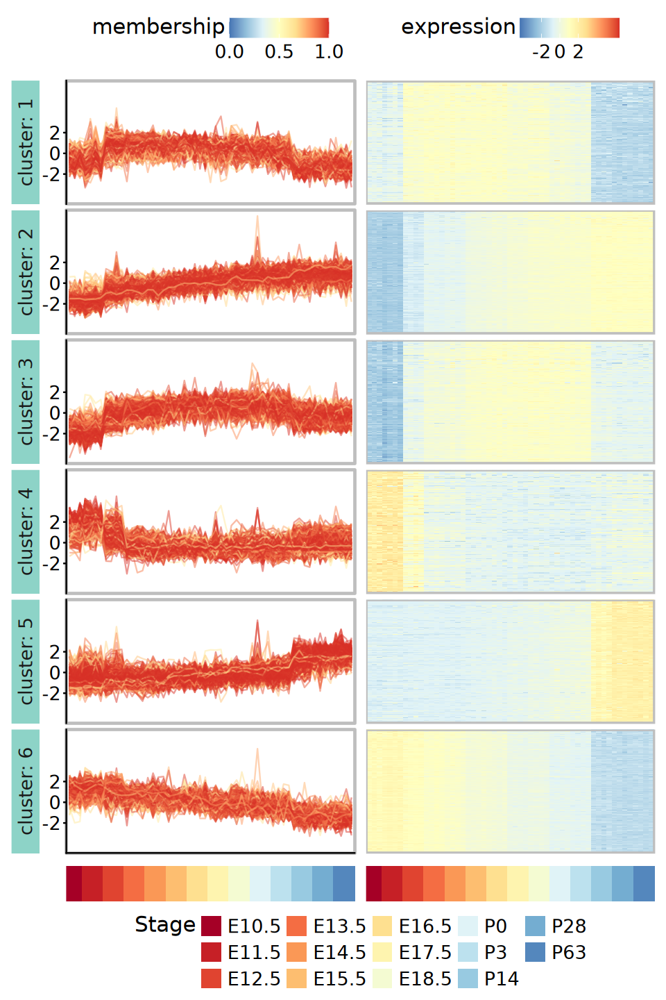

In [110]:
options(repr.plot.width = 8, repr.plot.height = 12)

(line_plot + heatmap_plot) / 
    (strip_plot + strip_plot + plot_layout(guides = "collect") & 
    theme(legend.position = "bottom")) + 
    plot_layout(heights = c(1, 0.05)) & 
    theme(strip.placement = "outside", plot.margin = margin(5, 5, 5, 5))

In [111]:
go_annotations <- ego_cluster_compare |> as.data.frame() |> 
    dplyr::select(Cluster, ONTOLOGY, ID, Description, p.adjust, Count) |>
    mutate(
        ONTOLOGY = factor(ONTOLOGY, levels = c("BP", "MF", "CC")),
        GO_term = paste0(Description, " (", ONTOLOGY, ")")) |>
    group_by(Cluster) |> 
    arrange(ONTOLOGY, p.adjust, .by_group = TRUE) |>
    slice_head(n = 5) |>
    summarise(GO_term = paste(GO_term, collapse = "\n")) |>
    left_join(
        plot_df |> group_by(cluster) |> 
            summarise(y_pos = mean(as.numeric(factor(gene_id)))), 
        by = c("Cluster" = "cluster"))
    
head(go_annotations)

Cluster,GO_term,y_pos
<fct>,<chr>,<dbl>
1,forebrain development (BP) forebrain neuron differentiation (BP) central nervous system neuron differentiation (BP) forebrain generation of neurons (BP) telencephalon development (BP),528.5
2,regulation of membrane potential (BP) neurotransmitter transport (BP) positive regulation of synaptic transmission (BP) regulation of synaptic plasticity (BP) vesicle-mediated transport in synapse (BP),1031.0
3,cell-cell adhesion via plasma-membrane adhesion molecules (BP) homophilic cell adhesion via plasma membrane adhesion molecules (BP) axonogenesis (BP) regulation of synapse structure or activity (BP) synapse assembly (BP),655.5
4,epithelial tube morphogenesis (BP) morphogenesis of a branching structure (BP) embryonic limb morphogenesis (BP) embryonic appendage morphogenesis (BP) morphogenesis of a branching epithelium (BP),350.0
5,positive regulation of MAPK cascade (BP) regulation of monoatomic ion transport (BP) neuropeptide signaling pathway (BP) intermediate filament organization (BP) ensheathment of neurons (BP),721.0
6,chromosome segregation (BP) DNA replication (BP) ribonucleoprotein complex biogenesis (BP) nuclear chromosome segregation (BP) sister chromatid segregation (BP),1095.5


In [112]:
annotation_plot <- ggplot(go_annotations, aes(x = 0, y = y_pos)) +
    geom_text(
        aes(color = GO_term, label = GO_term), 
        hjust = 0, size = 4, show.legend = FALSE) +
    facet_wrap(~ Cluster, ncol = 1, scales = "free_y") +
    scale_color_brewer(palette = "Dark2") + 
    xlim(c(0, 1)) +
    theme_test() + 
    theme(
        strip.text = element_blank(),
        axis.title = element_blank(),
        axis.text = element_blank(),
        axis.ticks = element_blank())

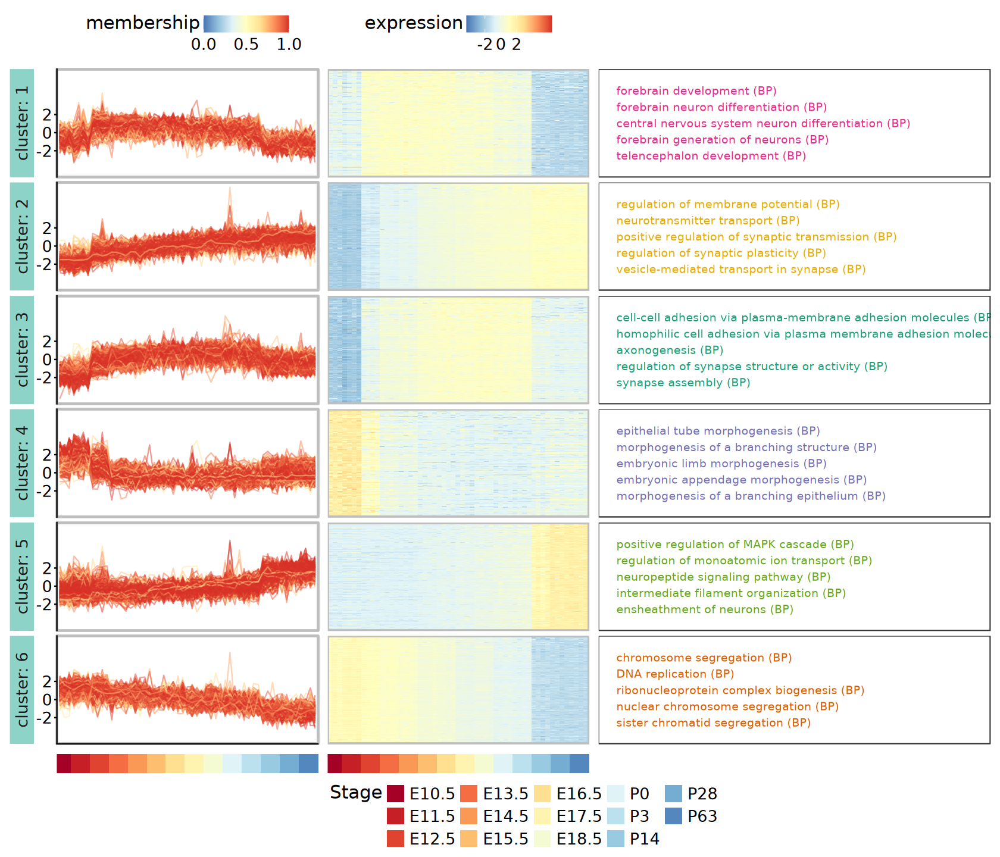

In [113]:
options(repr.plot.width = 14, repr.plot.height = 12)
top_row <- line_plot + heatmap_plot + annotation_plot +
    plot_layout(widths = c(2, 2, 3))
bottom_row <- strip_plot + strip_plot + plot_spacer() +
    plot_layout(widths = c(2, 2, 3), guides = "collect") & 
    theme(legend.position = "bottom")

top_row / bottom_row + 
    plot_layout(heights = c(1, 0.03)) &
    theme(
        plot.margin = margin(5, 5, 5, 5),
        strip.placement = "outside")

#### 2). ComplexHeatmap

In [114]:
# suppressPackageStartupMessages(library(circlize))
suppressPackageStartupMessages(library(ComplexHeatmap))

In [115]:
cluster_df <- cluster_df |>
    mutate(cluster = factor(paste0("cluster", cluster)))

In [116]:
ac <- colData(dds) |> 
    as.data.frame() |>
    dplyr::select(Stage, Sex, Replicate)

group_colors <- setNames(
    colorRampPalette(brewer.pal(11, "RdYlBu"))(nlevels(dds$Stage)),
    levels(dds$Stage))
sex_colors <- setNames(
    scales::brewer_pal(palette = "Set1")(nlevels(dds$Sex)),
    levels(dds$Sex))
replicate_colors <- setNames(
    scales::brewer_pal(palette = "Set2")(nlevels(dds$Replicate)),
    levels(dds$Replicate))

top_anno <- HeatmapAnnotation(
    df = ac, col = list(
        Stage = group_colors, 
        Sex = sex_colors,
        Replicate = replicate_colors))

In [117]:
ar <- cluster_df |> 
    dplyr::select(gene_id, Cluster = cluster) |>
    column_to_rownames("gene_id") |>
    arrange(Cluster)

cluster_colors <- setNames(
    scales::brewer_pal(palette = "Set3")(nlevels(ar$Cluster)),
    levels(ar$Cluster))

left_anno <- rowAnnotation(
    df = ar, col = list(Cluster = cluster_colors),
    show_legend = FALSE)

In [118]:
heatmap_dat <- norm_mat[rownames(ar), ]

heatmap_col <- circlize::colorRamp2(
    breaks = c(-2, 0, 2), 
    colors = brewer.pal(n = 11, name = "RdYlBu")[c(3,6,9)] |> rev())

In [119]:
gene_labels <- cluster_df |>
    filter(type == "protein_coding") |>
    group_by(cluster) |>
    slice_max(order_by = membership, n = 5, with_ties = FALSE) |>
    ungroup()

mark_rows <- which(rownames(heatmap_dat) %in% gene_labels$gene_id)
mark_labels <- gene_labels$symbol[
    match(rownames(heatmap_dat)[mark_rows], 
    gene_labels$gene_id)]

right_anno <- rowAnnotation(
    foo = anno_mark(
        at = mark_rows,
        labels = mark_labels,
        labels_gp = gpar(fontsize = 12)),
    width = unit(2.5, "cm"))

In [120]:
lg_heatmap <- Legend(
    title = "Expression (z-score)", col_fun = heatmap_col)

lg_group <- Legend(
    title = "Stage", labels = levels(dds$Stage))

lg_replicate <- Legend(
    title = "Replicate", labels = levels(dds$Replicate))

lg_cluster <- Legend(
    labels = levels(ar$Cluster), title = "Cluster", 
    legend_gp = gpar(fill = cluster_colors))

combined_leg <- list(lg_heatmap, lg_group, lg_replicate) |>
    packLegend(direction = "vertical")

In [121]:
ht <- heatmap_dat |> t() |> scale() |> t() |>
    Heatmap(
        name = "Expression", col = heatmap_col, 
        row_split = factor(ar$Cluster),
        cluster_row_slices = FALSE, cluster_columns = FALSE,
        top_annotation = top_anno,
        left_annotation = left_anno, 
        right_annotation = right_anno,
        show_row_names = FALSE, show_column_names = FALSE, 
        use_raster = TRUE)

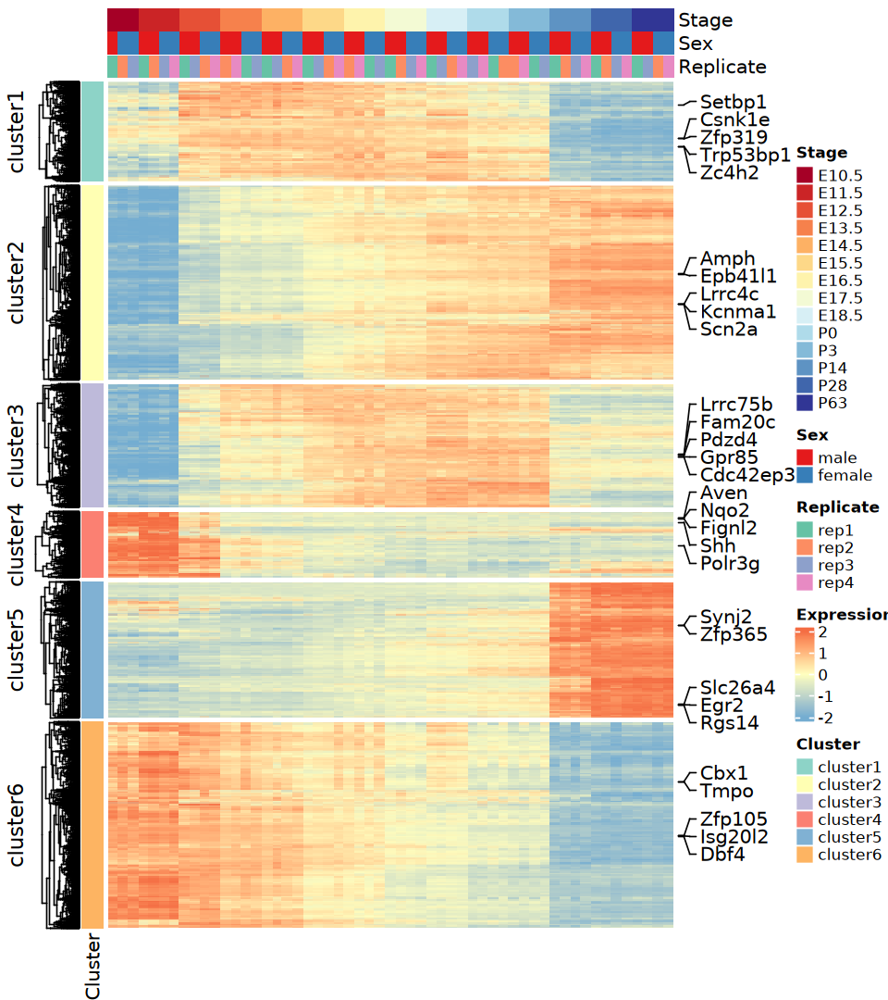

In [122]:
options(repr.plot.width = 8, repr.plot.height = 9)
draw(
    ht + combined_leg, merge_legend = TRUE,
    annotation_legend_list = list(lg_cluster), 
    legend_title_gp = gpar(fontsize = 12, fontface = "bold"),
    legend_labels_gp = gpar(fontsize = 10), 
    padding = unit(c(2, 2, 2, 2), "mm"))

In [123]:
go_annotations <- ego_cluster_compare |> as.data.frame() |> 
    dplyr::select(Cluster, ONTOLOGY, ID, Description, p.adjust, Count) |>
    mutate(
        ONTOLOGY = factor(ONTOLOGY, levels = c("BP", "MF", "CC")),
        GO_term = paste0(Description, " (", ONTOLOGY, ")")) |>
    group_by(Cluster) |> 
    arrange(ONTOLOGY, p.adjust, .by_group = TRUE) |>
    slice_head(n = 5) |>
    summarise(GO_term = paste(GO_term, collapse = "\n")) |>
    mutate(Cluster = factor(paste0("cluster", Cluster)))

head(go_annotations)

Cluster,GO_term
<fct>,<chr>
cluster1,forebrain development (BP) forebrain neuron differentiation (BP) central nervous system neuron differentiation (BP) forebrain generation of neurons (BP) telencephalon development (BP)
cluster2,regulation of membrane potential (BP) neurotransmitter transport (BP) positive regulation of synaptic transmission (BP) regulation of synaptic plasticity (BP) vesicle-mediated transport in synapse (BP)
cluster3,cell-cell adhesion via plasma-membrane adhesion molecules (BP) homophilic cell adhesion via plasma membrane adhesion molecules (BP) axonogenesis (BP) regulation of synapse structure or activity (BP) synapse assembly (BP)
cluster4,epithelial tube morphogenesis (BP) morphogenesis of a branching structure (BP) embryonic limb morphogenesis (BP) embryonic appendage morphogenesis (BP) morphogenesis of a branching epithelium (BP)
cluster5,positive regulation of MAPK cascade (BP) regulation of monoatomic ion transport (BP) neuropeptide signaling pathway (BP) intermediate filament organization (BP) ensheathment of neurons (BP)
cluster6,chromosome segregation (BP) DNA replication (BP) ribonucleoprotein complex biogenesis (BP) nuclear chromosome segregation (BP) sister chromatid segregation (BP)


In [124]:
go_term_data_list <- split(go_annotations$GO_term, go_annotations$Cluster)

In [125]:
right_annotation <- rowAnnotation(
    textbox = anno_textbox(
        ar$Cluster, go_term_data_list,
        background_gp = gpar(fill = "#ffffff"),
        gp = gpar(fontsize = 12), max_width = unit(10, "cm"), 
        add_new_line = TRUE, round_corners = TRUE), 
    width = unit(12, "cm"))
# word_wrap = TRUE, 

In [126]:
ht <- heatmap_dat |> t() |> scale() |> t() |>
    Heatmap(
        name = "Expression", col = heatmap_col, 
        row_split = factor(ar$Cluster),
        top_annotation = top_anno,
        left_annotation = left_anno, 
        right_annotation = right_anno,
        cluster_row_slices = FALSE, cluster_columns = FALSE,
        show_row_names = FALSE, show_column_names = FALSE, 
        width = unit(8, "cm"), use_raster = TRUE) +
    Heatmap(
        ar$Cluster, name = "Cluster", 
        col = cluster_colors,
        show_column_names = FALSE,
        right_annotation = right_annotation,
        width = unit(0.3, "cm"))

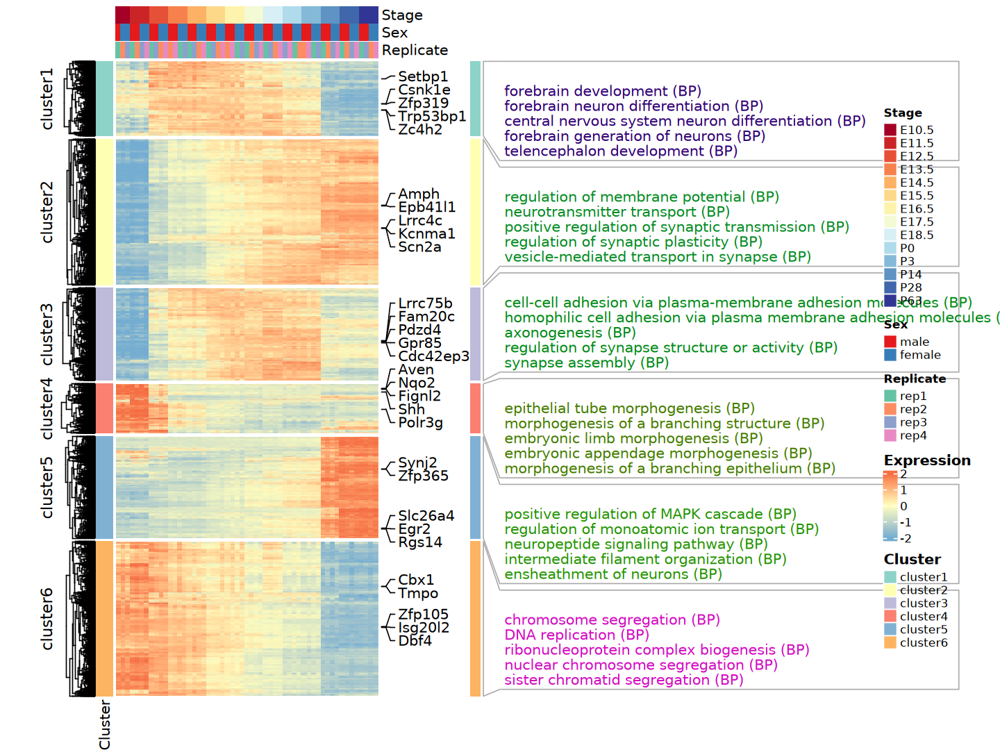

In [127]:
options(repr.plot.width = 12, repr.plot.height = 9)
draw(
    ht + combined_leg, merge_legend = TRUE,
    # annotation_legend_list = list(lg_cluster), 
    legend_title_gp = gpar(fontsize = 12, fontface = "bold"),
    legend_labels_gp = gpar(fontsize = 10), 
    padding = unit(c(2, 2, 2, 2), "mm"))

In [128]:
s_heatmap_dat <- heatmap_dat |> t() |> scale() |> t()

In [129]:
panel_fun_boxplot <- function(s_heatmap_dat, group_colors = NULL) {
    function(index, nm) {
        tmp <- s_heatmap_dat[index, , drop = FALSE]
        pos <- seq(0, 1, length.out = ncol(tmp))
        rng <- range(tmp, na.rm = TRUE)
        norm <- (tmp - rng[1]) / (rng[2] - rng[1])
        fills <- if (is.null(group_colors)) "grey70" else group_colors |>
            rep(each = 3)
        bw <- min(0.1, 0.9 / max(1, ncol(tmp)))

        grid::pushViewport(grid::viewport(xscale = c(-0.1, 1.1), yscale = c(0, 1.2)))
        grid::grid.rect()                         
        for (i in seq_len(ncol(norm))) {
            grid.boxplot(
                norm[, i], pos = pos[i],
                direction = "vertical",
                box_width = bw, outline = FALSE,
                gp = grid::gpar(col = "grey50", fill = fills[i]))
        }
        grid::grid.lines(
            x = pos, y = apply(norm, 2, median, na.rm = TRUE),
            gp = grid::gpar(col = "red", lwd = 0.5))
        grid::grid.text(
            paste0("Genes: ", nrow(tmp)), 0.5, 0.9, 
            gp = grid::gpar(fontsize = 6))
        grid::popViewport()
    }
}

In [130]:
panel_fun <- panel_fun_boxplot(s_heatmap_dat, group_colors)
left_anno2 <- rowAnnotation(
    boxplot = anno_link(
        align_to = factor(ar$Cluster), which = "row",
        panel_fun = panel_fun, side = "left",
        size = grid::unit(3, "cm"),
        width = grid::unit(6, "cm"),
        gap = grid::unit(0.25, "cm"),
        link_gp = grid::gpar(fill = "grey90", col = NA)))

In [131]:
ht <- heatmap_dat |> t() |> scale() |> t() |>
    Heatmap(
        name = "Expression", col = heatmap_col, 
        row_split = factor(ar$Cluster),
        top_annotation = top_anno,
        left_annotation = left_anno2, 
        right_annotation = right_anno,
        cluster_row_slices = FALSE, cluster_columns = FALSE,
        show_row_names = FALSE, show_column_names = FALSE, 
        show_row_dend = FALSE,
        width = unit(8, "cm"), use_raster = TRUE) +
    Heatmap(
        ar$Cluster, name = "Cluster", 
        col = cluster_colors,
        show_column_names = FALSE,
        right_annotation = right_annotation,
        width = unit(0.3, "cm"))

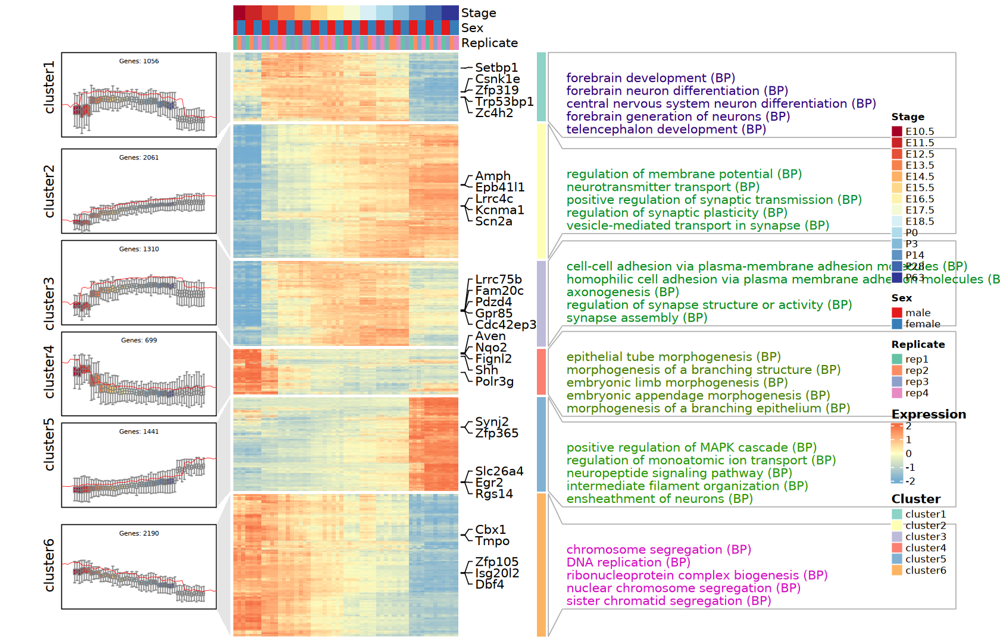

In [132]:
options(repr.plot.width = 14, repr.plot.height = 9)
draw(
    ht + combined_leg, merge_legend = TRUE,
    # annotation_legend_list = list(lg_cluster), 
    legend_title_gp = gpar(fontsize = 12, fontface = "bold"),
    legend_labels_gp = gpar(fontsize = 10), 
    padding = unit(c(2, 2, 2, 2), "mm"))

In [133]:
panel_fun_pathplot <- function(
    s_heatmap_dat, cluster_df, palette = c("blue","white","red")) {
    
    function(index, nm) {
        tmp <- s_heatmap_dat[index, , drop = FALSE]
        # pos <- scales::rescale(1:ncol(tmp), to = c(0, 1))
        pos <- seq(0, 1, length.out = ncol(tmp))
        rng <- range(tmp, na.rm = TRUE)
        norm <- (tmp - rng[1]) / (rng[2] - rng[1])
        
        mem <- cluster_df$membership[match(rownames(tmp), cluster_df$gene_id)]
        mem_idx <- round(mem * 100)
        line_colors <- grDevices::colorRampPalette(palette)(100)
        line_cols <- line_colors[mem_idx]

        pushViewport(grid::viewport(xscale = c(-0.1, 1.1), yscale = c(0, 1.2)))
        grid.rect()
        for (i in seq_len(nrow(norm))) {
            grid.lines(
                x = pos, y = norm[i, ], 
                gp = gpar(col = line_cols[i], lwd = 0.5))
        }
        grid.text(paste0("Genes: ", nrow(tmp)), 0.5, 0.9, gp = grid::gpar(fontsize = 6))
        popViewport()
    }
}

In [134]:
palette = c(
    "#5E4FA2", "#3288BD", "#66C2A5", "#ABDDA4", 
    "#E6F598", "#FFFFBF", "#FEE08B", "#FDAE61", 
    "#F46D43", "#D53E4F", "#9E0142")

In [135]:
panel_fun <- panel_fun_pathplot(s_heatmap_dat, cluster_df, palette)
left_anno3 <- rowAnnotation(
    boxplot = anno_link(
        align_to = factor(ar$Cluster), which = "row",
        panel_fun = panel_fun, side = "left",
        size = grid::unit(3, "cm"),
        width = grid::unit(6, "cm"),
        gap = grid::unit(0.25, "cm"),
        link_gp = grid::gpar(fill = "grey90", col = NA)))

In [136]:
line_colors <- circlize::colorRamp2(
    breaks = seq(0, 1, length.out = length(palette)), 
    colors = palette)

lg_line <- Legend(
    title = "Membership", col_fun = line_colors, 
    at = c(0, 0.5, 1), labels = c("0", "0.5", "1"))

In [137]:
combined_leg <- list(lg_heatmap, lg_group, lg_replicate, lg_line) |>
    packLegend(direction = "vertical")

In [138]:
ht <- heatmap_dat |> t() |> scale() |> t() |>
    Heatmap(
        name = "Expression", col = heatmap_col, 
        row_split = factor(ar$Cluster),
        top_annotation = top_anno,
        left_annotation = left_anno3, 
        right_annotation = right_anno,
        cluster_row_slices = FALSE, cluster_columns = FALSE,
        show_row_names = FALSE, show_column_names = FALSE, 
        show_row_dend = FALSE,
        width = unit(8, "cm"), use_raster = TRUE) +
    Heatmap(
        ar$Cluster, name = "Cluster", 
        col = cluster_colors,
        show_column_names = FALSE,
        right_annotation = right_annotation,
        width = unit(0.3, "cm"))

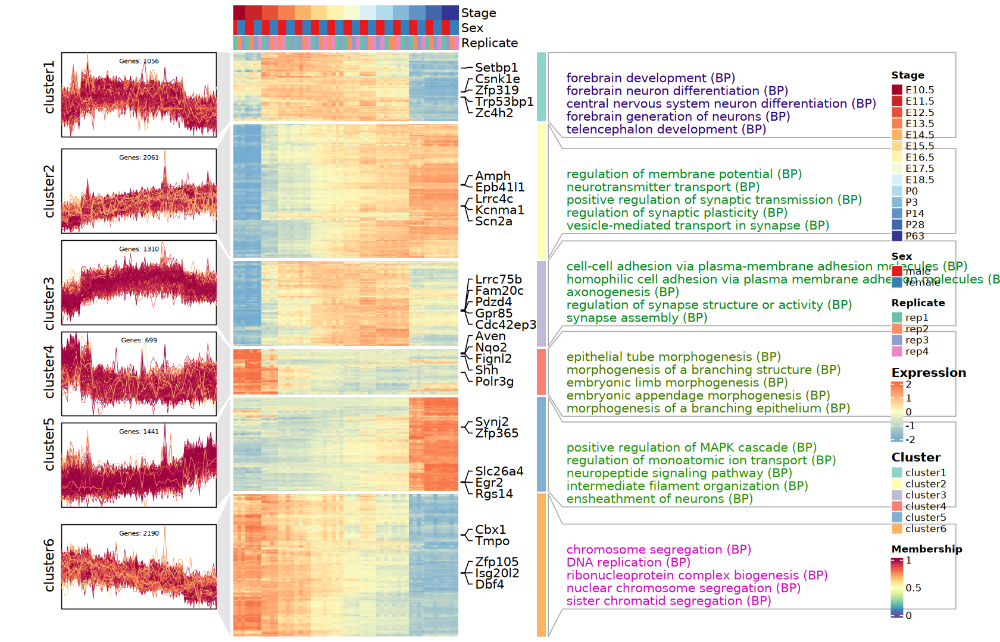

In [139]:
options(repr.plot.width = 14, repr.plot.height = 9)
draw(
    ht + combined_leg, merge_legend = TRUE,
    annotation_legend_list = list(lg_line),
    legend_title_gp = gpar(fontsize = 12, fontface = "bold"),
    legend_labels_gp = gpar(fontsize = 10), 
    padding = unit(c(2, 2, 2, 2), "mm"))

#### 3). [ClusterGVis](https://github.com/junjunlab/ClusterGVis)

> - To enhance clustering and visualization of time-series gene expression data from RNA-Seq experiments.

In [140]:
suppressPackageStartupMessages(library(ClusterGVis))

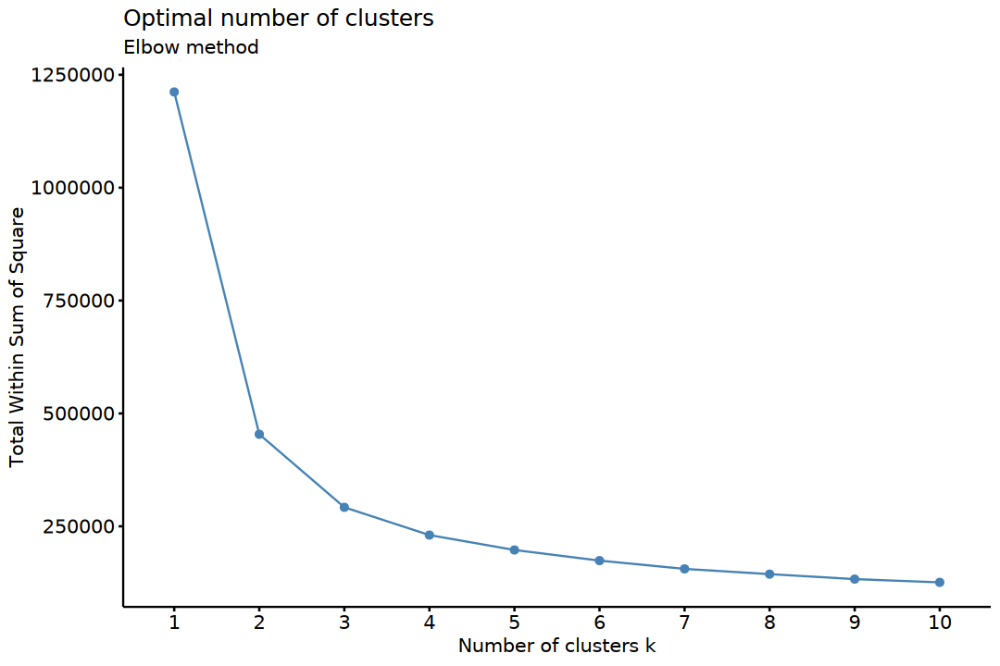

In [141]:
options(repr.plot.width = 9, repr.plot.height = 6)
getClusters(norm_mean_mat)
# ~ 2 min

In [142]:
cl <- clusterData(norm_mean_mat, cluster.method = "mfuzz", cluster.num = 6)

[1] "0 genes excluded.\n"


Warning message:
“Using `size` aesthetic for lines was deprecated in ggplot2 3.4.0.
ℹ Please use `linewidth` instead.
ℹ The deprecated feature was likely used in the ClusterGVis package.
  Please report the issue at <https://github.com/junjunlab/ClusterGVis/issues>.”


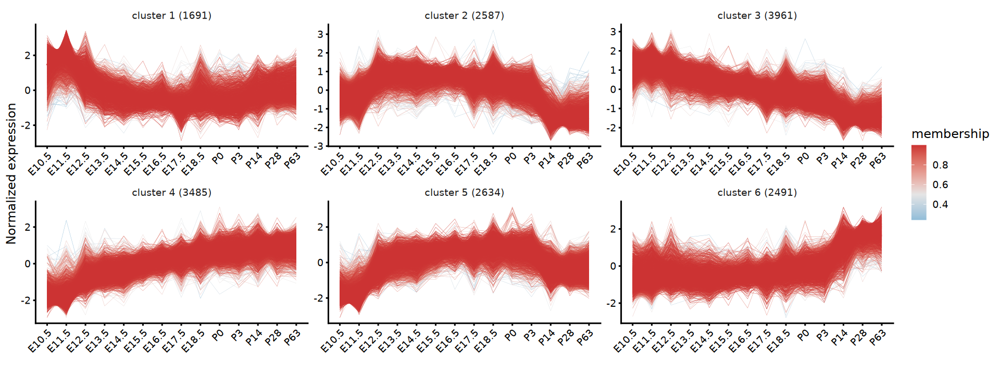

In [143]:
options(repr.plot.width = 16, repr.plot.height = 6)
visCluster(object = cl, plot.type = "line", ncol = 3)

In [144]:
markGenes = rownames(norm_mean_mat)[
    sample(1:nrow(norm_mean_mat), 30, replace = F)]

In [145]:
go_annotations <- ego_cluster_compare |> as.data.frame() |> 
    dplyr::select(Cluster, ONTOLOGY, ID, Description, p.adjust, Count) |>
    mutate(
        ONTOLOGY = factor(ONTOLOGY, levels = c("BP", "MF", "CC")), 
        GO_term = paste0(Description, " (", ONTOLOGY, ")")) |>
    group_by(Cluster) |> 
    arrange(ONTOLOGY, p.adjust, .by_group = TRUE) |>
    slice_head(n = 5) |>
    ungroup() |>
    mutate(Cluster = factor(paste0("C", Cluster))) |>
    dplyr::select(id = Cluster, term = GO_term)

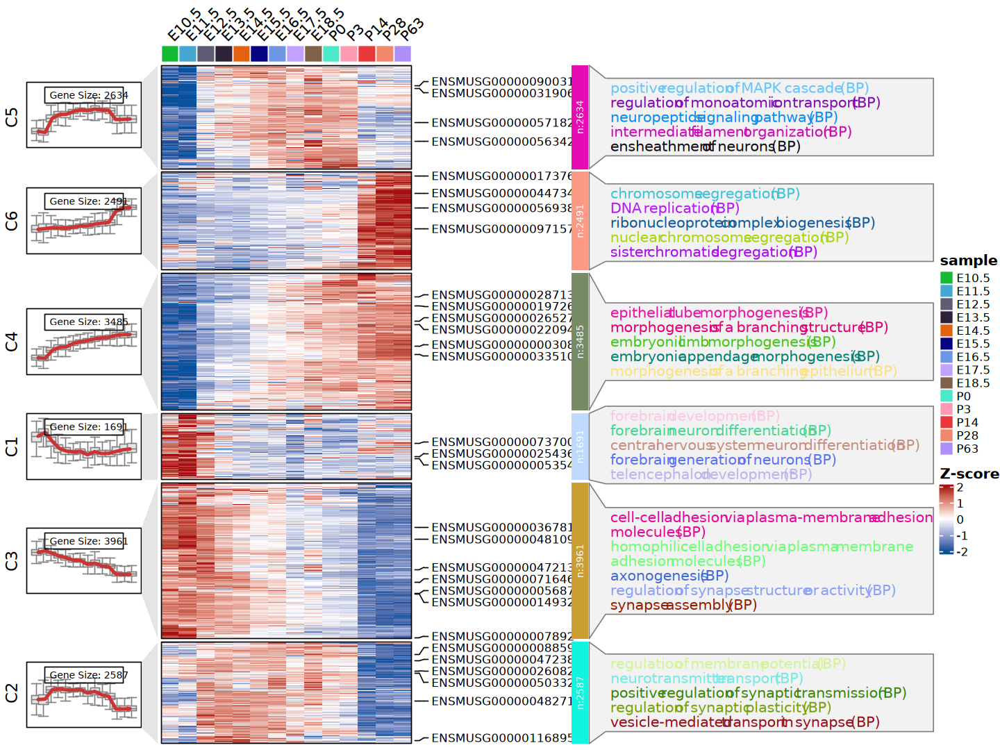

In [146]:
options(repr.plot.width = 12, repr.plot.height = 9)
visCluster(
    object = cl, 
    # HeatmapAnnotation = top_anno,
    plot.type = "both", line.side = "left", add.box = TRUE,
    markGenes = markGenes, genes.gp = c('italic', 10, "black"),
    annoTerm.data = go_annotations, 
    column_names_rot = 45, show_row_dend = FALSE)

In [147]:
go_annotations <- ego_cluster_compare |> as.data.frame() |> 
    mutate(ONTOLOGY = factor(ONTOLOGY, levels = c("BP", "MF", "CC"))) |>
    group_by(Cluster) |> 
    arrange(ONTOLOGY, qvalue, .by_group = TRUE) |>
    slice_head(n = 5) |>
    ungroup() |>
    dplyr::select(group = Cluster, Description, qvalue, ratio = Count) |>
    mutate(group = factor(paste0("C", group)))

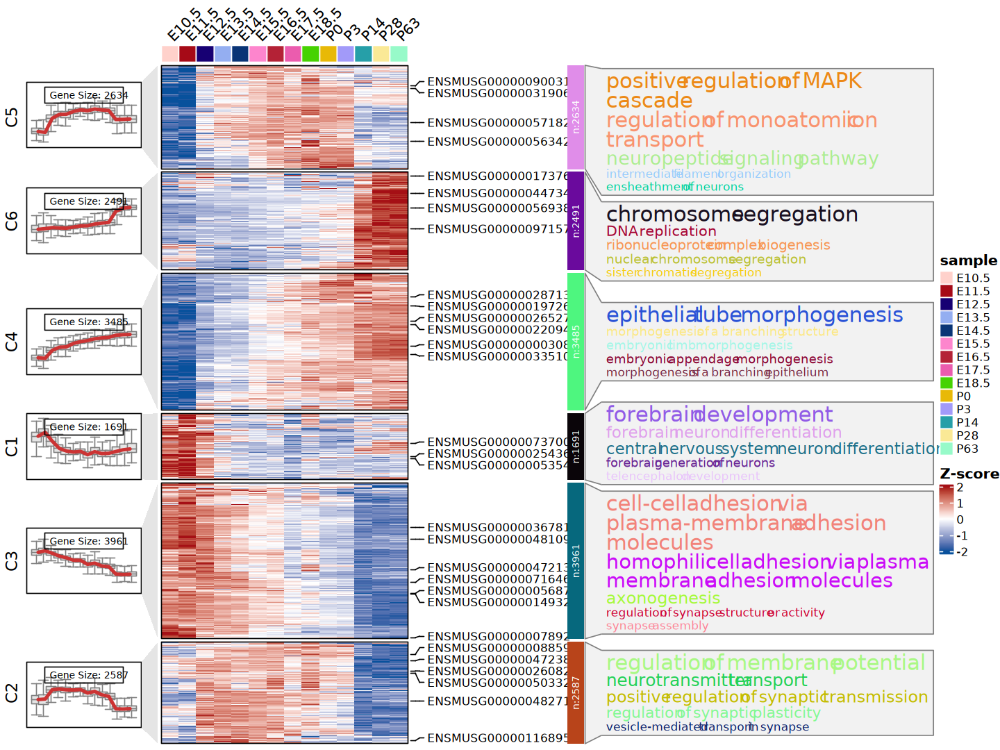

In [148]:
options(repr.plot.width = 12, repr.plot.height = 9)
visCluster(
    object = cl, 
    # HeatmapAnnotation = top_anno,
    plot.type = "both", line.side = "left", add.box = TRUE,
    markGenes = markGenes, genes.gp = c('italic', 10, "black"),
    annoTerm.data = go_annotations, go.size = "pval",
    # go.col = rep(ggsci::pal_d3()(6), each = 5), 
    column_names_rot = 45, show_row_dend = FALSE)

# Reference

> 1. Law CW, Alhamdoosh M, Su S, Dong X, Tian L, Smyth GK, Ritchie ME (2018). “RNA-seq analysis is easy as 1-2-3 with limma, Glimma and edgeR.” F1000Research, 5, 1408. https://f1000research.com/articles/5-1408/v3. [RNA-seq analysis is easy as 1-2-3 with limma, Glimma and edgeR](https://www.bioconductor.org/packages/release/workflows/html/RNAseq123.html)
> 2. Law CW, Zeglinski K, Dong X, Alhamdoosh M, Smyth GK, Ritchie ME (2020). “A guide to creating design matrices for gene expression experiments.” F1000Research, 9, 1444. https://f1000research.com/articles/9-1444. [A guide to creating design matrices for gene expression experiments](https://www.bioconductor.org/packages/release/workflows/vignettes/RNAseq123/inst/doc/designmatrices.html)
> 2. Love MI, Anders S, Kim V, Huber W (2016). “RNA-Seq workflow: gene-level exploratory analysis and differential expression.” F1000Research. doi:10.12688/f1000research.7035.2. [RNA-seq workflow: gene-level exploratory analysis and differential expression](https://www.bioconductor.org/packages/release/workflows/html/rnaseqGene.html)
> 3. Chen Y, Lun ATL, Smyth GK (2016). “From reads to genes to pathways: differential expression analysis of RNA-Seq experiments using Rsubread and the edgeR quasi-likelihood pipeline.” F1000Research, 5, 1438. http://f1000research.com/articles/5-1438. [Gene-level RNA-seq differential expression and pathway analysis using Rsubread and the edgeR quasi-likelihood pipeline](https://www.bioconductor.org/packages/release/workflows/html/RnaSeqGeneEdgeRQL.html)